# Lecture 7 Companion Notebook: The Normal Distribution
**INFSCI/PS 0702 · University of Pittsburgh**

This notebook walks through the ideas from Lecture 7 with code and **seaborn** visualizations, then extends them to examples from computational social science.

**Readings:** *The Model Thinker* (Ch. 5), *Probably Overthinking It* (Ch. 1), *The Secret Life of Data* (Ch. 2)

| Part | Topic | Lecture slides |
|---|---|---|
| 1 | The normal curve, ranges, and anomalies | 2–3 |
| 2 | The Central Limit Theorem (and when it fails) | 4–7 |
| 3 | Human height: a sum of many small factors | 9–15 |
| 4 | CDFs and joint distributions | 16–18 |
| 5 | The "average" man and the Big Five: we are all weird | 19–27 |
| 6 | Sampling and the most dangerous equation | 28–31 |
| 7 | Computational social science: distributions and conclusions | 32–42 |
| 8 | Exercises | — |

### A note about the data
The lecture uses two real datasets: the US Army **ANSUR II** body-measurement survey and an online **Big Five** personality survey, as analyzed by Allen Downey. To keep this notebook self-contained (it runs without downloading anything), every dataset here is **simulated**. Where possible, the simulations use the means and standard deviations reported in the lecture tables; where the lecture doesn't give a value (for example, correlations between body measurements), the notebook states the assumption it makes. Treat the exact numbers as illustrations, and the *patterns* as the lesson.

If you want to work with the real data, Downey's notebooks for *Probably Overthinking It* show how to load ANSUR II and the Big Five survey; the analysis code below works the same way on a real DataFrame.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

rng = np.random.default_rng(702)   # fixed seed so results are reproducible

PITT_BLUE, PITT_GOLD = "#003594", "#FFB81C"
PALETTE = [PITT_BLUE, PITT_GOLD, "#6C8EBF", "#B85C38", "#5B8C5A", "#8E6FB8"]
sns.set_theme(style="whitegrid", context="notebook", palette=PALETTE)
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.precision", 3)
print("numpy", np.__version__, "| pandas", pd.__version__, "| seaborn", sns.__version__)

numpy 2.4.6 | pandas 3.0.3 | seaborn 0.13.2


# Part 1 — The normal curve

## 1.1 The 68–95–99.7 rule
A normal distribution is described by two numbers: its mean $\mu$ and standard deviation $\sigma$. The **standard normal** has $\mu = 0$ and $\sigma = 1$. Any normal variable $X$ can be converted to it with the **z-score** $z = (x - \mu)/\sigma$.

The plot below shades the regions within 1, 2, and 3 standard deviations of the mean (slide 2).

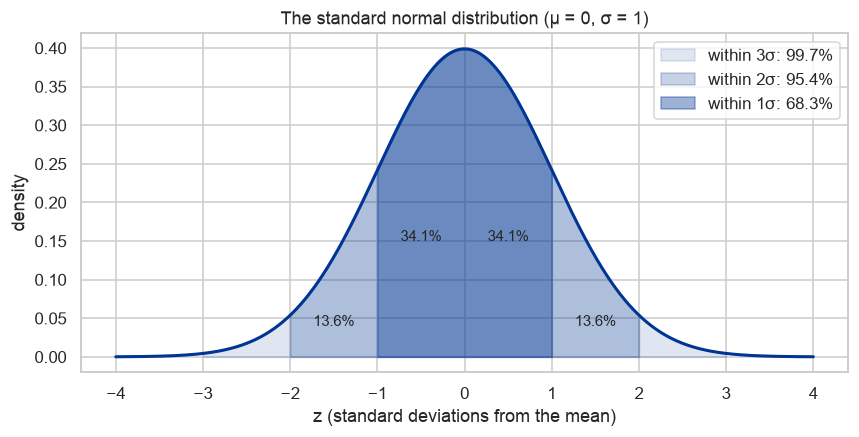

In [2]:
x = np.linspace(-4, 4, 801)
pdf = stats.norm.pdf(x)

fig, ax = plt.subplots(figsize=(9, 4))
for k, alpha in [(3, 0.12), (2, 0.22), (1, 0.38)]:
    inside = np.abs(x) <= k
    share = stats.norm.cdf(k) - stats.norm.cdf(-k)
    ax.fill_between(x[inside], pdf[inside], color=PITT_BLUE, alpha=alpha,
                    label=f"within {k}σ: {share:.1%}")
sns.lineplot(x=x, y=pdf, color=PITT_BLUE, lw=2, ax=ax, legend=False)
for lo, hi, ypos in [(0, 1, 0.15), (1, 2, 0.04)]:
    p = stats.norm.cdf(hi) - stats.norm.cdf(lo)
    for sign in (1, -1):
        ax.text(sign * (lo + hi) / 2, ypos, f"{p:.1%}", ha="center", fontsize=10)
ax.set(title="The standard normal distribution (μ = 0, σ = 1)", xlabel="z (standard deviations from the mean)",
       ylabel="density")
ax.legend(loc="upper right")
plt.show()

## 1.2 How rare is "far from the mean"?
Slide 3 says a 5σ event has roughly a 1-in-2-million chance. The table computes the exact tail probabilities.

In [3]:
rows = []
for k in [1, 2, 3, 4, 5, 6]:
    two_tail = 2 * stats.norm.sf(k)
    rows.append({"k (σ from mean)": k,
                 "P(|Z| > k)": two_tail,
                 "about 1 in": f"{1 / two_tail:,.0f}",
                 "P(Z > k), one tail": stats.norm.sf(k)})
tails = pd.DataFrame(rows)
display(tails)

,k (σ from mean),P(|Z| > k),about 1 in,"P(Z > k), one tail"
0,1,3.173e-01,3,1.587e-01
1,2,4.550e-02,22,2.275e-02
2,3,2.700e-03,370,1.350e-03
3,4,6.334e-05,"15,787",3.167e-05
4,5,5.733e-07,"1,744,278",2.867e-07
5,6,1.973e-09,"506,797,346",9.866e-10


The normal tails shrink *very* fast: going from 3σ to 5σ makes an event about 2,000 times rarer. This is why a very extreme observation is often better evidence that **the normal model is wrong** than evidence of an extraordinary coincidence.

## 1.3 Ranges: houses in Milwaukee
With $\mu = 2000$ ft² and $\sigma = 500$ ft², about 95% of houses lie within $\mu \pm 1.96\sigma$.

Theoretical middle 95%: 1,020 to 2,980 sq ft
Simulated   middle 95%: 1,026 to 2,986 sq ft


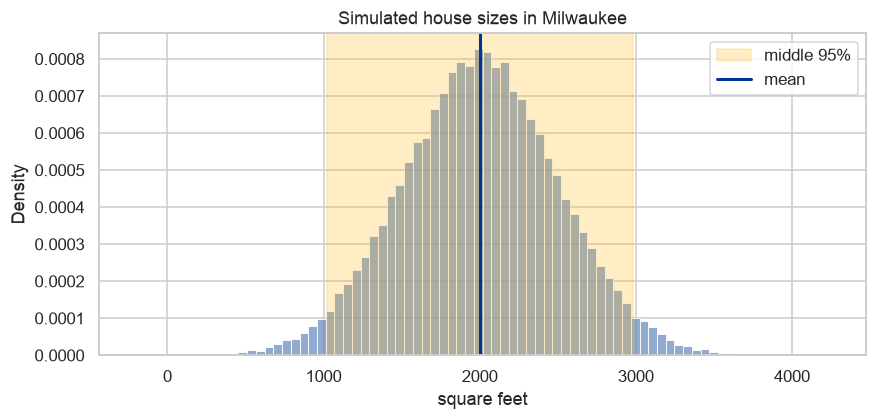

In [4]:
mu, sigma = 2000, 500
houses = rng.normal(mu, sigma, 50_000)

lo, hi = stats.norm.ppf([0.025, 0.975], mu, sigma)
emp_lo, emp_hi = np.percentile(houses, [2.5, 97.5])
print(f"Theoretical middle 95%: {lo:,.0f} to {hi:,.0f} sq ft")
print(f"Simulated   middle 95%: {emp_lo:,.0f} to {emp_hi:,.0f} sq ft")

fig, ax = plt.subplots(figsize=(9, 3.8))
sns.histplot(houses, bins=80, stat="density", color=PALETTE[2], ax=ax)
ax.axvspan(lo, hi, color=PITT_GOLD, alpha=0.25, label="middle 95%")
ax.axvline(mu, color=PITT_BLUE, lw=2, label="mean")
ax.set(title="Simulated house sizes in Milwaukee", xlabel="square feet")
ax.legend()
plt.show()

## 1.4 Lemon or super-mileage anomaly?
Suppose a car model averages 30 mpg with σ = 1.5 mpg. We simulate a fleet of 5,000 cars and secretly add 6 cars with real problems (or unusually good engines). Flagging cars with $|z| > 3$ finds most of the planted anomalies, but it also flags ordinary cars, because with thousands of cars a 3σ result is *expected* to happen by chance a few times.

Cars flagged with |z| > 3: 22
  of which planted anomalies: 6 of 6
Ordinary cars expected beyond 3σ by chance alone: about 13.5


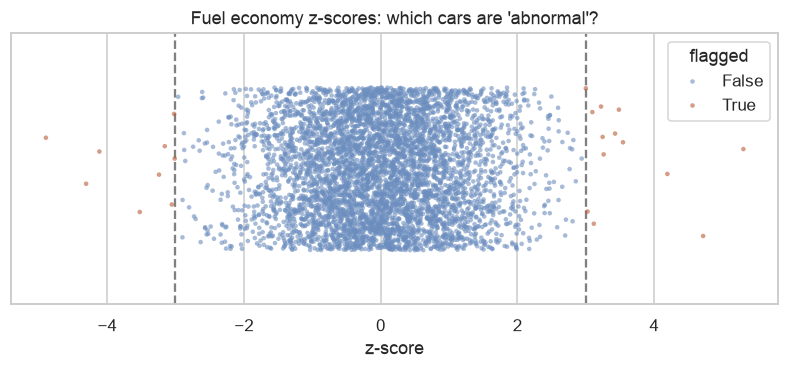

In [5]:
n_cars = 5000
mpg = rng.normal(30, 1.5, n_cars)
planted = rng.choice(n_cars, 6, replace=False)
mpg[planted] = [22.5, 23.4, 24.6, 36.4, 37.2, 38.1]

fleet = pd.DataFrame({"mpg": mpg, "planted": False})
fleet.loc[planted, "planted"] = True
fleet["z"] = (fleet.mpg - fleet.mpg.mean()) / fleet.mpg.std()
fleet["flagged"] = fleet.z.abs() > 3

expected_false_flags = n_cars * 2 * stats.norm.sf(3)
print(f"Cars flagged with |z| > 3: {fleet.flagged.sum()}")
print(f"  of which planted anomalies: {(fleet.flagged & fleet.planted).sum()} of {len(planted)}")
print(f"Ordinary cars expected beyond 3σ by chance alone: about {expected_false_flags:.1f}")

fig, ax = plt.subplots(figsize=(9, 3.2))
sns.stripplot(data=fleet, x="z", hue="flagged", palette={False: PALETTE[2], True: PALETTE[3]},
              jitter=0.3, size=3, alpha=0.6, ax=ax)
ax.axvline(-3, ls="--", color="gray"); ax.axvline(3, ls="--", color="gray")
ax.set(title="Fuel economy z-scores: which cars are 'abnormal'?", xlabel="z-score", yticks=[])
plt.show()

**Takeaway.** A z-score threshold is a useful screen, but how many "anomalies" you find depends on how many things you look at. This multiple-comparisons problem returns in Part 6 and Part 7.


# Part 2 — The Central Limit Theorem

> The sum of $N \geq 20$ random variables will be approximately normal **provided** the variables are independent, each has a finite variance, and no small set of them contributes most of the variance. The variables themselves need not be normal. (slide 4)

## 2.1 Sums of non-normal variables become normal
Below, we add up $N$ draws from four very non-normal distributions and standardize each sum. The gray curve is the standard normal.

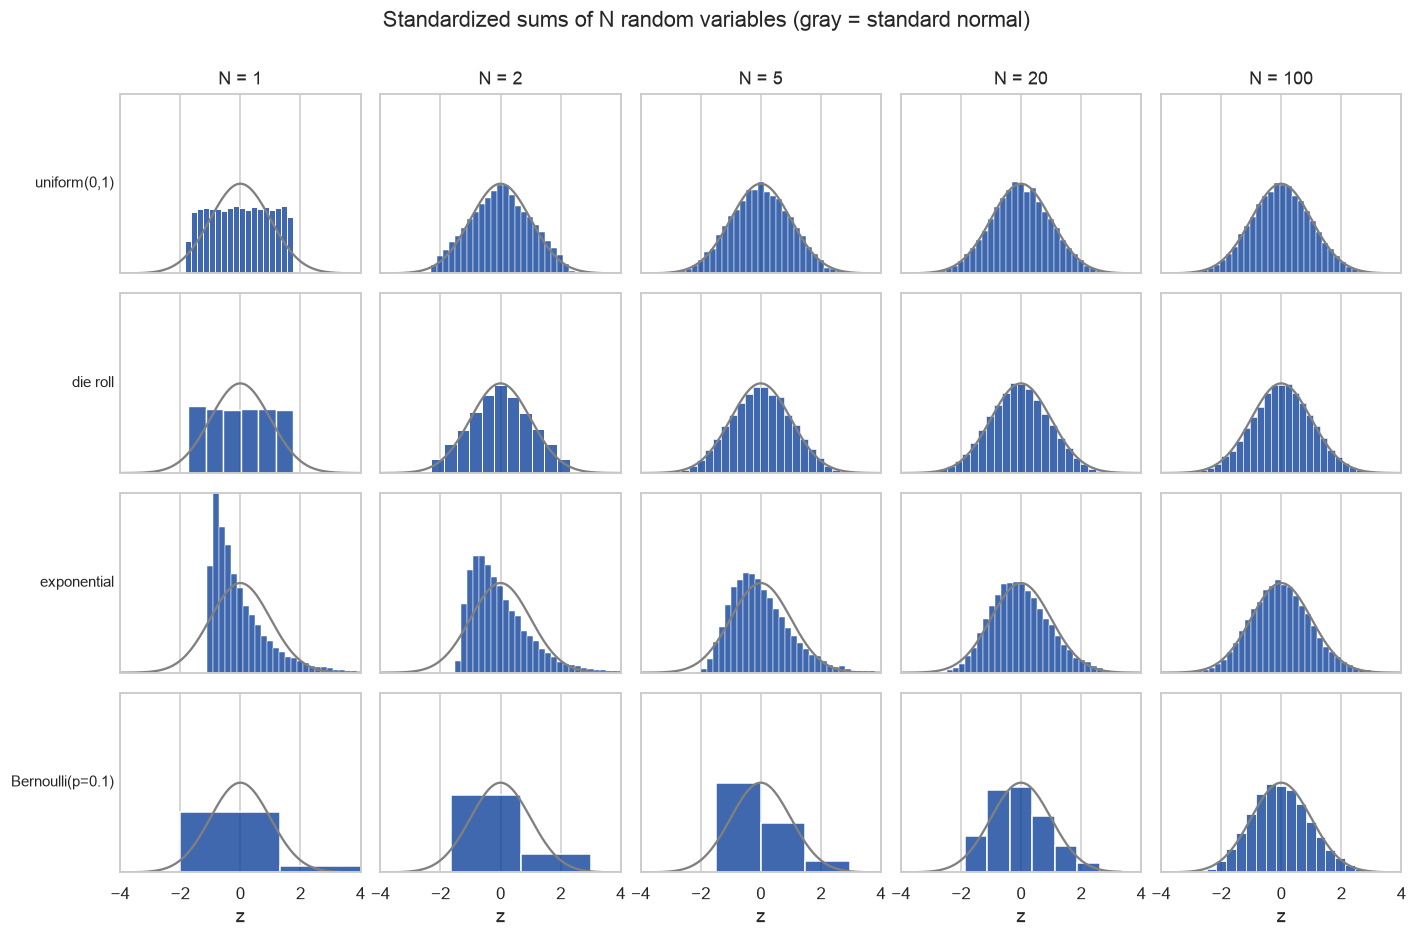

In [6]:
def draw(dist, size):
    if dist == "uniform(0,1)":
        return rng.uniform(0, 1, size)
    if dist == "die roll":
        return rng.integers(1, 7, size)
    if dist == "exponential":
        return rng.exponential(1.0, size)
    if dist == "Bernoulli(p=0.1)":
        return rng.binomial(1, 0.1, size)

dists = ["uniform(0,1)", "die roll", "exponential", "Bernoulli(p=0.1)"]
Ns = [1, 2, 5, 20, 100]
records = []
for d in dists:
    for n in Ns:
        sums = draw(d, (20_000, n)).sum(axis=1)
        z = (sums - sums.mean()) / sums.std()
        # for integer-valued sums, z only takes values spaced 1/sd apart
        spacing = 1 / sums.std() if d in ("die roll", "Bernoulli(p=0.1)") else 0.2
        records.append(pd.DataFrame({"distribution": d, "N": n, "z": z, "spacing": spacing}))
clt = pd.concat(records, ignore_index=True)

fig, axes = plt.subplots(len(dists), len(Ns), figsize=(13, 8.5), sharex=True)
zz = np.linspace(-4, 4, 200)
for i, d in enumerate(dists):
    for j, n in enumerate(Ns):
        ax = axes[i, j]
        sub = clt[(clt.distribution == d) & (clt.N == n)]
        sp = sub.spacing.iloc[0]
        w = sp * np.ceil(0.2 / sp - 1e-9)             # a whole number of lattice steps, at least 0.2 wide
        start = sub.z.min() - w / 2
        sns.histplot(sub, x="z", stat="density", bins=np.arange(start, sub.z.max() + w, w),
                     color=PITT_BLUE, ax=ax)
        ax.plot(zz, stats.norm.pdf(zz), color="gray", lw=1.5)
        ax.set(xlim=(-4, 4), ylim=(0, 0.8), ylabel="", yticks=[], xlabel="z" if i == len(dists) - 1 else "")
        if i == 0:
            ax.set_title(f"N = {n}")
        if j == 0:
            ax.set_ylabel(d, rotation=0, ha="right", va="center", fontsize=10)
fig.suptitle("Standardized sums of N random variables (gray = standard normal)", y=1.0)
plt.tight_layout(); plt.show()

In [7]:
skew = (clt.groupby(["distribution", "N"]).z
        .agg(lambda s: stats.skew(s)).unstack("N").round(2))
print("Skewness of the standardized sum (0 = symmetric like the normal):")
display(skew)

Skewness of the standardized sum (0 = symmetric like the normal):


N,1,2,5,20,100
distribution,,,,,
Bernoulli(p=0.1),2.66,1.82,1.17,0.59,0.26
die roll,0.00,0.01,-0.01,0.01,-0.00
exponential,2.02,1.39,0.91,0.47,0.23
"uniform(0,1)",-0.01,0.00,-0.00,0.02,-0.01


Symmetric inputs (uniform, die rolls) look normal almost immediately. Skewed inputs (exponential, a rare Bernoulli event) need many more terms; the skewness shrinks roughly like $1/\sqrt{N}$. "$N \geq 20$" is a rule of thumb, not a guarantee.

## 2.2 When the CLT fails
Each condition in the theorem matters. Here we break them one at a time, using sums of 50 terms.

1. **Infinite variance**: Cauchy-distributed terms. A single huge draw can dominate the sum.
2. **Dependence**: every term shares a common shock (think: a town-wide event that affects everyone's spending).
3. **One term dominates**: 49 small terms plus one large on/off term.

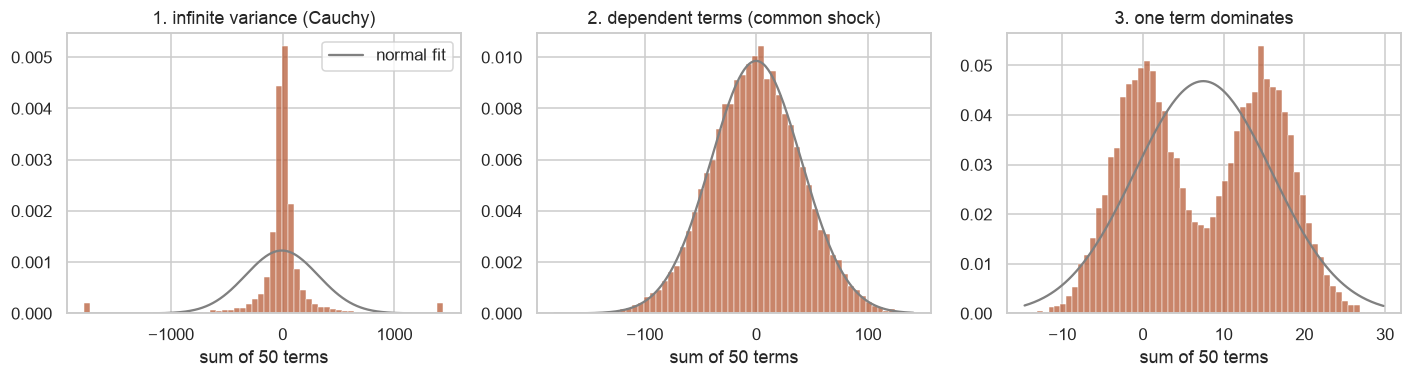

Share of the dependent sums beyond 3 'naive' SDs (assuming independence): 59.8% — versus 0.3% expected if the terms were independent


In [8]:
n, reps = 50, 20_000
cauchy = rng.standard_cauchy((reps, n)).sum(axis=1)

shock = rng.normal(0, 1, (reps, 1))                     # shared by every term
dependent = (0.8 * shock + 0.6 * rng.normal(0, 1, (reps, n))).sum(axis=1)

dominant = rng.uniform(-1, 1, (reps, n - 1)).sum(axis=1) + 15 * rng.binomial(1, 0.5, reps)

fails = pd.DataFrame({
    "1. infinite variance (Cauchy)": cauchy,
    "2. dependent terms (common shock)": dependent,
    "3. one term dominates": dominant,
})
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, fails.columns):
    s = fails[col]
    if "Cauchy" in col:
        s = s.clip(*np.percentile(s, [1, 99]))          # clip for display only
    sns.histplot(s, bins=60, stat="density", ax=ax, color=PALETTE[3])
    xs = np.linspace(s.min(), s.max(), 300)
    ax.plot(xs, stats.norm.pdf(xs, s.mean(), s.std()), color="gray", lw=1.5, label="normal fit")
    ax.set(title=col, xlabel="sum of 50 terms", ylabel="")
axes[0].legend()
plt.tight_layout(); plt.show()

print("Share of the dependent sums beyond 3 'naive' SDs (assuming independence):",
      f"{(np.abs(dependent) > 3 * np.sqrt(n * (0.8**2 + 0.6**2))).mean():.1%}",
      "— versus 0.3% expected if the terms were independent")

The dependent case can still *look* bell-shaped, but it is far wider than an independence-based calculation predicts. That is often the most dangerous failure in social data: the shape looks fine, but the uncertainty is badly underestimated.

## 2.3 The small town (slides 5–7)
500 residents each spend \$100/week on average, with three spending "styles":

- **Alice-type:** \$50 or \$150 (we draw these at random each week rather than strictly alternating, so each week is independent),
- **Bob-type:** \$300 one week in three, otherwise \$0,
- **Prashant-type:** random amounts (a gamma distribution with mean \$100).

We simulate 3,000 weeks and look at the town's total weekly spending.

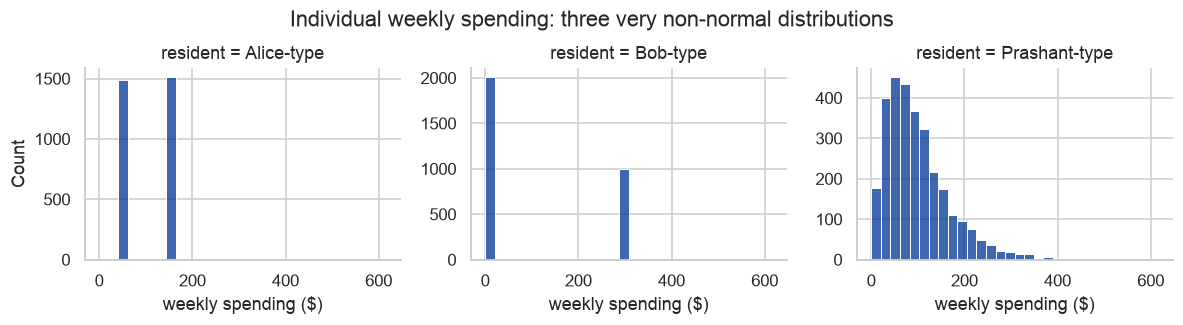

In [9]:
n_people, n_weeks = 500, 3000
types = rng.choice(["Alice", "Bob", "Prashant"], n_people)

def weekly_spending(types, n_weeks, rng):
    out = np.empty((n_weeks, len(types)))
    a, b, p = types == "Alice", types == "Bob", types == "Prashant"
    out[:, a] = rng.choice([50, 150], (n_weeks, a.sum()))
    out[:, b] = 300 * rng.binomial(1, 1/3, (n_weeks, b.sum()))
    out[:, p] = rng.gamma(shape=2.0, scale=50.0, size=(n_weeks, p.sum()))   # mean 100, sd ~71
    return out

spend = weekly_spending(types, n_weeks, rng)

# individual spending patterns
people = pd.DataFrame({
    "Alice-type": spend[:, np.where(types == "Alice")[0][0]],
    "Bob-type": spend[:, np.where(types == "Bob")[0][0]],
    "Prashant-type": spend[:, np.where(types == "Prashant")[0][0]],
}).melt(var_name="resident", value_name="weekly spending ($)")
g = sns.displot(people, x="weekly spending ($)", col="resident", bins=30, height=2.8, aspect=1.3,
                color=PITT_BLUE, facet_kws={"sharey": False})
g.fig.suptitle("Individual weekly spending: three very non-normal distributions", y=1.05)
plt.show()

Mean weekly total:       $49,938   (theory: $50,000)
SD of weekly total:      $2,189   (theory, independent: $2,166)
Relative variation: individuals ≈ 50–140% of the mean; town total ≈ 4.4%


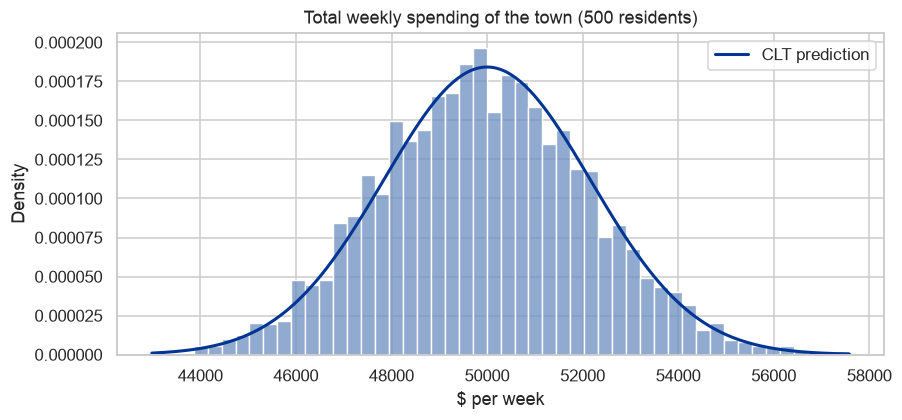

In [10]:
total = spend.sum(axis=1)
person_sd = {"Alice": 50.0, "Bob": np.sqrt(300**2 / 3 - 100**2), "Prashant": np.sqrt(2.0) * 50.0}
predicted_sd = np.sqrt(sum(person_sd[t] ** 2 for t in types))

print(f"Mean weekly total:       ${total.mean():,.0f}   (theory: $50,000)")
print(f"SD of weekly total:      ${total.std():,.0f}   (theory, independent: ${predicted_sd:,.0f})")
print(f"Relative variation: individuals ≈ 50–140% of the mean; town total ≈ {total.std()/total.mean():.1%}")

fig, ax = plt.subplots(figsize=(9, 3.8))
sns.histplot(total, bins=50, stat="density", color=PALETTE[2], ax=ax)
xs = np.linspace(total.min(), total.max(), 300)
ax.plot(xs, stats.norm.pdf(xs, 50_000, predicted_sd), color=PITT_BLUE, lw=2, label="CLT prediction")
ax.set(title="Total weekly spending of the town (500 residents)", xlabel="$ per week")
ax.legend(); plt.show()

### Is spending really independent?
Paydays, holidays, and snowstorms move *everyone's* spending together. Below we add a town-wide weekly multiplier (mean 1, SD 5%) and compare. The total is still bell-shaped, but much wider than the independence-based CLT prediction.

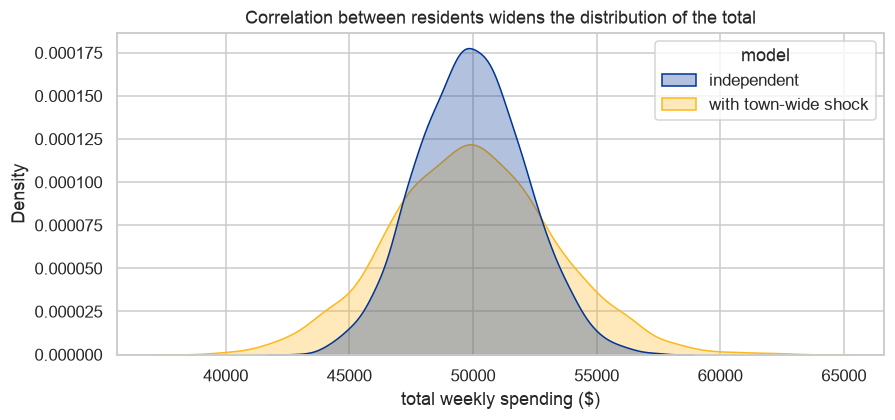

SD independent: $2,189   SD with shared shock: $3,348

If 50 residents leave: mean falls by $4,993; SD changes from $2,189 to $2,081 (≈ √(450/500) = 0.95×)


In [11]:
town_shock = rng.normal(1.0, 0.05, (n_weeks, 1))
total_corr = (spend * town_shock).sum(axis=1)

compare = pd.DataFrame({"independent": total, "with town-wide shock": total_corr}).melt(
    var_name="model", value_name="total weekly spending ($)")
fig, ax = plt.subplots(figsize=(9, 3.8))
sns.kdeplot(data=compare, x="total weekly spending ($)", hue="model", fill=True, common_norm=False,
            alpha=0.3, ax=ax)
ax.set(title="Correlation between residents widens the distribution of the total")
plt.show()
print(f"SD independent: ${total.std():,.0f}   SD with shared shock: ${total_corr.std():,.0f}")

# Slide 7: 50 people leave town
keep = rng.choice(n_people, n_people - 50, replace=False)
total_450 = spend[:, keep].sum(axis=1)
print(f"\nIf 50 residents leave: mean falls by ${total.mean() - total_450.mean():,.0f}; "
      f"SD changes from ${total.std():,.0f} to ${total_450.std():,.0f} "
      f"(≈ √(450/500) = {np.sqrt(450/500):.2f}×)")


# Part 3 — Human height as a sum of many small factors (slides 9–15)

Following Downey, each simulated person has a set of binary factors (an allele, a nutrient deficiency, an infection…). Each factor has a fixed effect drawn uniformly from −3 to +3 cm. A person's height is a baseline plus the effects of the factors that apply to them.

**Assumptions:** 60 factors, each applying to a person with probability ½. The baselines are set so the simulated means match approximate ANSUR values (men 175.6 cm, from the lecture table; women about 162.9 cm). We do **not** tune the spread; it emerges from the factors.

In [12]:
n_factors = 60
effects = rng.uniform(-3, 3, n_factors)          # fixed effect of each factor (cm)

def simulate_heights(n, target_mean, rng):
    bits = rng.binomial(1, 0.5, (n, n_factors))  # which factors apply to each person
    raw = bits @ effects
    return target_mean + raw - raw.mean(), bits

male_h, male_bits = simulate_heights(4086, 175.6, rng)
female_h, _ = simulate_heights(1986, 162.9, rng)

heights = pd.concat([pd.DataFrame({"height (cm)": female_h, "group": "Female"}),
                     pd.DataFrame({"height (cm)": male_h, "group": "Male"})], ignore_index=True)
print(heights.groupby("group")["height (cm)"].agg(["count", "mean", "std"]).round(2))
print("Lecture table (male stature): mean 175.6, SD 6.9")

        count   mean   std
group                     
Female   1986  162.9  6.82
Male     4086  175.6  6.72
Lecture table (male stature): mean 175.6, SD 6.9


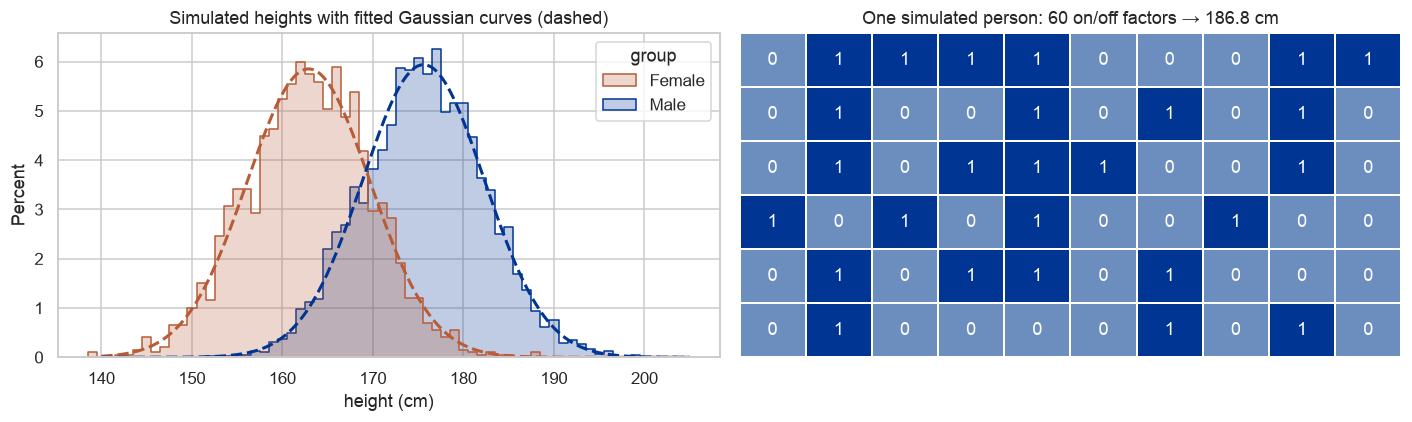

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(data=heights, x="height (cm)", hue="group", element="step", stat="percent",
             common_norm=False, binwidth=1, palette=[PALETTE[3], PITT_BLUE], alpha=0.25, ax=axes[0])
xs = np.linspace(140, 205, 400)
for grp, col in [("Female", PALETTE[3]), ("Male", PITT_BLUE)]:
    h = heights.loc[heights.group == grp, "height (cm)"]
    axes[0].plot(xs, 100 * stats.norm.pdf(xs, h.mean(), h.std()), color=col, lw=2, ls="--")
axes[0].set(title="Simulated heights with fitted Gaussian curves (dashed)")

# one simulated person's factors, as on slide 13
person = pd.DataFrame(male_bits[0].reshape(6, 10))
sns.heatmap(person, cmap=[PALETTE[2], PITT_BLUE], cbar=False, annot=True, fmt="d",
            linewidths=1, linecolor="white", ax=axes[1])
axes[1].set(title=f"One simulated person: 60 on/off factors → {male_h[0]:.1f} cm",
            xticks=[], yticks=[])
plt.tight_layout(); plt.show()

### Checking normality with a Q–Q plot
A **quantile–quantile (Q–Q) plot** compares the quantiles of the data to the quantiles of a normal distribution. If the data are normal, the points fall on a straight line.

The lecture notes that one ANSUR measurement is *not* normal: **weight**. Weight behaves more like a *product* of factors than a sum (effects compound), and products of positive factors tend to be **log-normal** and right-skewed. We simulate that by multiplying factors instead of adding them.

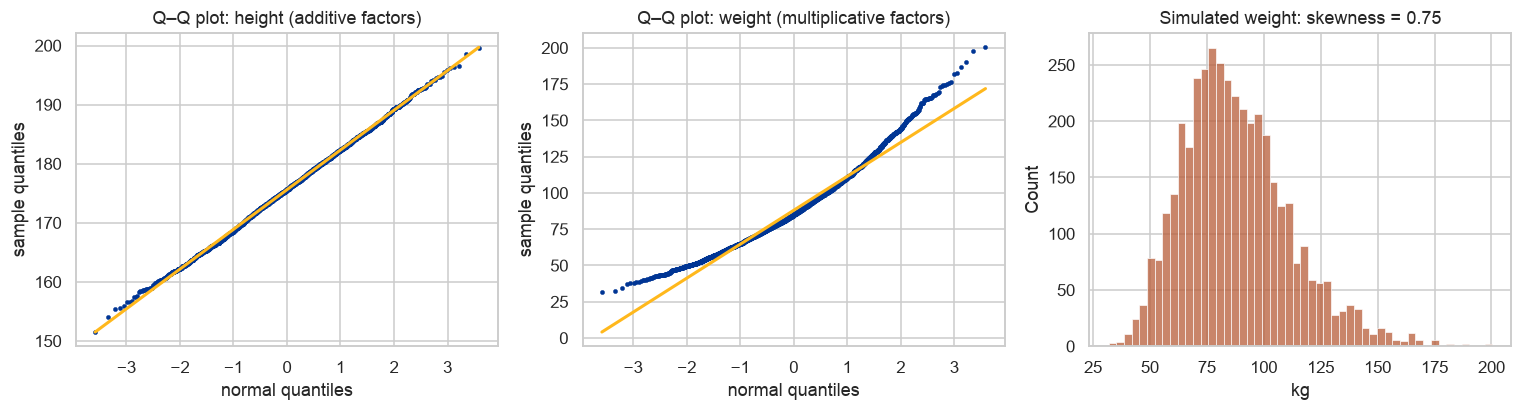

Skewness of height: 0.01   Skewness of weight: 0.75


In [14]:
mult_effects = rng.uniform(0.97, 1.03, n_factors)       # each factor changes weight by up to ±3%
bits = rng.binomial(1, 0.5, (4086, n_factors))
raw_w = np.prod(np.where(bits == 1, mult_effects, 1.0) ** 4, axis=1)   # effects compound
weight = 85 * raw_w / np.median(raw_w)                                 # kg, median set to 85

fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
for ax, data, label in [(axes[0], male_h, "height (additive factors)"),
                        (axes[1], weight, "weight (multiplicative factors)")]:
    (osm, osr), (slope, intercept, r) = stats.probplot(data, dist="norm")
    sns.scatterplot(x=osm, y=osr, s=8, color=PITT_BLUE, edgecolor=None, ax=ax)
    ax.plot(osm, slope * osm + intercept, color=PITT_GOLD, lw=2)
    ax.set(title=f"Q–Q plot: {label}", xlabel="normal quantiles", ylabel="sample quantiles")
sns.histplot(weight, bins=50, color=PALETTE[3], ax=axes[2])
axes[2].set(title=f"Simulated weight: skewness = {stats.skew(weight):.2f}", xlabel="kg")
plt.tight_layout(); plt.show()
print(f"Skewness of height: {stats.skew(male_h):.2f}   Skewness of weight: {stats.skew(weight):.2f}")

**Caveats (slide 15).** Real factors aren't limited to ±3 cm, they are correlated (poverty brings poor nutrition *and* more infections), and they interact rather than simply add. The additive model works for height because those complications are small *in aggregate*, not because they don't exist.


# Part 4 — CDFs and joint distributions (slides 16–18)

## 4.1 Percentile ranks and the CDF
The **cumulative distribution function** $F(x) = P(X \le x)$ gives the fraction of values at or below $x$. Multiplied by 100, it is the **percentile rank**. Unlike a histogram, a CDF doesn't depend on a choice of bins, which makes small departures from a model easier to see.

Following Downey's forearm-length figure (slide 16), we simulate a measurement that is *slightly* skewed, then compare its empirical CDF to a normal model. The gray band shows the range of CDFs you get from 100 truly normal samples of the same size, i.e., how much the CDF wiggles from sampling noise alone.

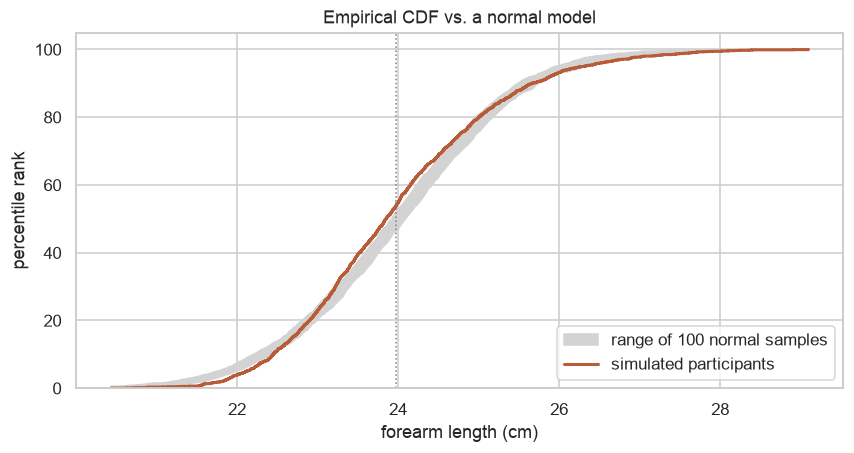

In [18]:
n = 1986
forearm = stats.skewnorm.rvs(a=2.5, loc=22.6, scale=1.9, size=n, random_state=rng)   # cm, mildly skewed
m, s = forearm.mean(), forearm.std()

grid = np.linspace(forearm.min(), forearm.max(), 300)
band = np.array([np.searchsorted(np.sort(rng.normal(m, s, n)), grid) / n for _ in range(100)])

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.fill_between(grid, 100 * band.min(axis=0), 100 * band.max(axis=0), color="lightgray",
                label="range of 100 normal samples")
sns.ecdfplot(x=forearm, stat="percent", color=PALETTE[3], lw=2, ax=ax, label="simulated participants")
ax.axvline(m, color="gray", ls=":", lw=1)
ax.set(title="Empirical CDF vs. a normal model", xlabel="forearm length (cm)", ylabel="percentile rank")
ax.legend(loc="lower right"); 
plt.show()


Where the orange curve leaves the gray band, the mismatch is larger than sampling noise. With large samples, formal tests (like the K–S test above) will detect even tiny departures from normality, so the useful question is usually *"is the normal model good enough for my purpose?"*, not *"is it exactly normal?"*

## 4.2 Joint distributions: being "average" on two things at once
Slide 17 asks for $P\{x_1 < X \le x_2,\; y_1 < Y \le y_2\}$. If $X$ and $Y$ are independent, the probability is just the product of the two marginal probabilities. If they are correlated, it isn't.

Below, $X$ and $Y$ are standard normal with correlation $\rho$. We ask how many people are "close to average" (within ±0.3σ) on **both**.

In [19]:
def bivariate(rho, n=200_000):
    cov = [[1, rho], [rho, 1]]
    return rng.multivariate_normal([0, 0], cov, n)

k = 0.3
p_single = stats.norm.cdf(k) - stats.norm.cdf(-k)
rows = []
for rho in [0, 0.3, 0.6, 0.8, 0.95]:
    xy = bivariate(rho)
    both = np.mean((np.abs(xy[:, 0]) < k) & (np.abs(xy[:, 1]) < k))
    rows.append({"correlation ρ": rho, "P(close on X)": p_single,
                 "P(close on both)": both, "if independent": p_single**2})
display(pd.DataFrame(rows))

,correlation ρ,P(close on X),P(close on both),if independent
0,0.00,0.236,0.056,0.056
1,0.30,0.236,0.057,0.056
2,0.60,0.236,0.067,0.056
3,0.80,0.236,0.087,0.056
4,0.95,0.236,0.142,0.056


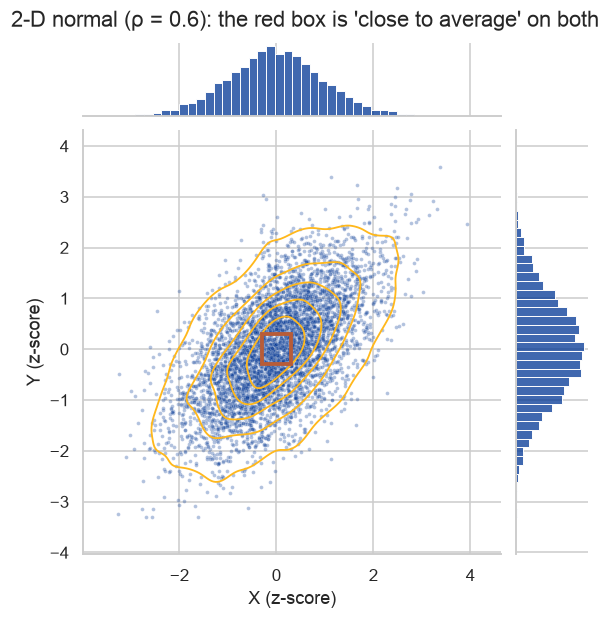

In [20]:
xy = pd.DataFrame(bivariate(0.6, 5000), columns=["X (z-score)", "Y (z-score)"])
g = sns.jointplot(data=xy, x="X (z-score)", y="Y (z-score)", kind="scatter", s=6, alpha=0.3,
                  color=PITT_BLUE, height=5.5, marginal_kws={"bins": 40})
g.plot_joint(sns.kdeplot, levels=6, color=PITT_GOLD, linewidths=1.2)
g.ax_joint.add_patch(plt.Rectangle((-k, -k), 2 * k, 2 * k, fill=False, ec=PALETTE[3], lw=2.5, zorder=10))
g.figure.suptitle("2-D normal (ρ = 0.6): the red box is 'close to average' on both", y=1.02)
plt.show()

The contours of a 2-D normal are **ellipses** (slide 18). Correlation stretches them along the diagonal, which puts more people in the central box than independence would, but still far fewer than on either measurement alone.

# Part 5 — The "average" man and the Big Five (slides 19–27)

## 5.1 Ten body measurements
We simulate 4,086 men using the means and standard deviations from **Downey's table** (slide 20). Real body measurements are correlated, so we generate them from two underlying factors: a **length** factor (height, limbs) and a **girth** factor (chest, waist, thigh), which are themselves moderately correlated.

**Assumption:** the factor loadings below are illustrative choices, not estimates from ANSUR. The exact counts will differ from Downey's; the pattern will not.

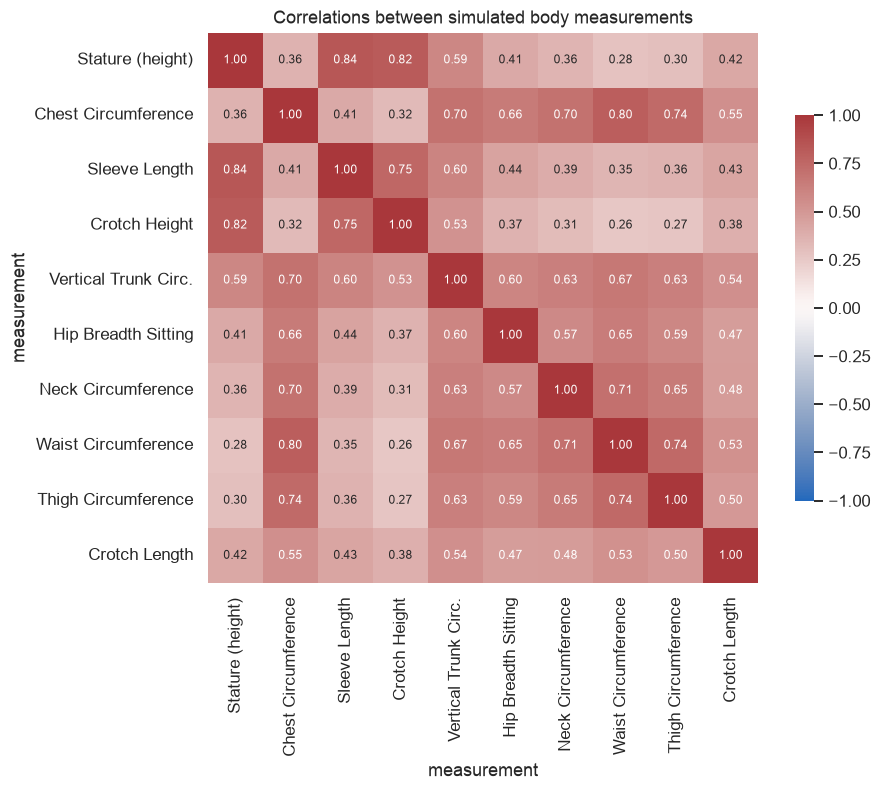

In [21]:
table = pd.DataFrame({
    "measurement": ["Stature (height)", "Chest Circumference", "Sleeve Length", "Crotch Height",
                    "Vertical Trunk Circ.", "Hip Breadth Sitting", "Neck Circumference",
                    "Waist Circumference", "Thigh Circumference", "Crotch Length"],
    "mean": [175.6, 105.9, 89.6, 84.6, 166.5, 37.9, 39.8, 94.1, 62.5, 35.6],
    "sd":   [6.9, 8.7, 4.0, 4.6, 9.0, 3.0, 2.6, 11.2, 5.8, 2.9],
    # loadings on (length factor, girth factor) — illustrative assumptions
    "load_length": [0.95, 0.15, 0.85, 0.85, 0.45, 0.25, 0.15, 0.05, 0.10, 0.30],
    "load_girth":  [0.00, 0.85, 0.10, 0.00, 0.60, 0.65, 0.75, 0.90, 0.80, 0.50],
})

def simulate_bodies(table, n, rng, factor_corr=0.3):
    F = rng.multivariate_normal([0, 0], [[1, factor_corr], [factor_corr, 1]], n)
    L = table[["load_length", "load_girth"]].to_numpy()
    common = F @ L.T
    common_var = np.var(common, axis=0)
    unique = rng.normal(0, 1, (n, len(table))) * np.sqrt(np.clip(1 - common_var, 0.05, None))
    z = common + unique
    z = (z - z.mean(axis=0)) / z.std(axis=0)
    return pd.DataFrame(table["mean"].to_numpy() + z * table["sd"].to_numpy(), columns=table.measurement)

bodies = simulate_bodies(table, 4086, rng)
corr = bodies.corr()
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 8}, square=True, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set(title="Correlations between simulated body measurements")
plt.show()

### Downey's "close to average" range
Downey calls a value "close to average" if it is within about **±0.3 standard deviations** of the mean. For a normal distribution that captures about 23.6% of people, matching the "% in range" column on slide 20.

In [22]:
K = 0.3
z = (bodies - bodies.mean()) / bodies.std()
close = z.abs() < K

summary = pd.DataFrame({
    "Mean": bodies.mean(), "Std Dev": bodies.std(),
    "Low": bodies.mean() - K * bodies.std(), "High": bodies.mean() + K * bodies.std(),
    "% in range": 100 * close.mean(),
}).round(1)
display(summary)

,Mean,Std Dev,Low,High,% in range
measurement,,,,,
Stature (height),175.6,6.9,173.5,177.7,22.7
Chest Circumference,105.9,8.7,103.3,108.5,23.5
Sleeve Length,89.6,4.0,88.4,90.8,22.7
Crotch Height,84.6,4.6,83.2,86.0,23.4
Vertical Trunk Circ.,166.5,9.0,163.8,169.2,23.2
Hip Breadth Sitting,37.9,3.0,37.0,38.8,23.3
Neck Circumference,39.8,2.6,39.0,40.6,24.0
Waist Circumference,94.1,11.2,90.7,97.5,24.2
Thigh Circumference,62.5,5.8,60.8,64.2,22.8


,step,measurement added,people remaining,if measurements were independent
0,1,Stature (height),927,927.0
1,2,Chest Circumference,235,218.3
2,3,Sleeve Length,100,49.5
3,4,Crotch Height,30,11.6
4,5,Vertical Trunk Circ.,13,2.7
5,6,Hip Breadth Sitting,3,0.6
6,7,Neck Circumference,1,0.2
7,8,Waist Circumference,1,0.0
8,9,Thigh Circumference,0,0.0
9,10,Crotch Length,0,0.0


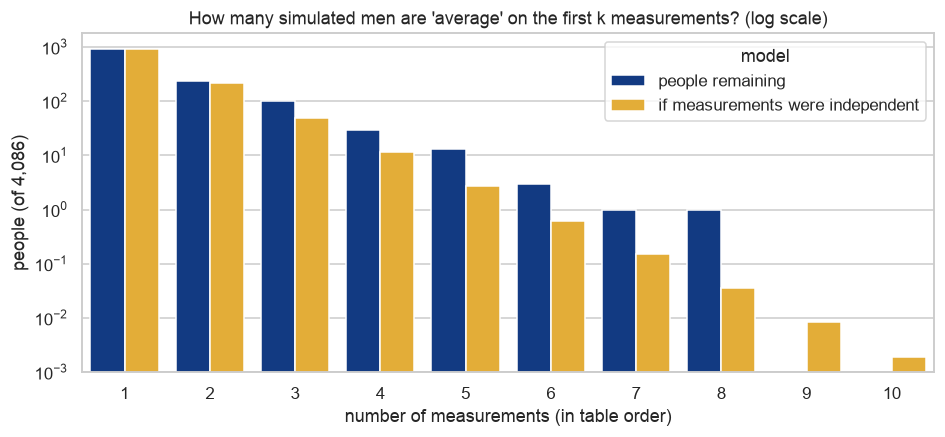

Downey's real ANSUR counts for the first three steps: 949 → 244 → 87


In [23]:
# The hurdle: keep only people who are close to average on each measurement in turn
remaining = np.ones(len(bodies), dtype=bool)
funnel = []
for i, col in enumerate(close.columns):
    remaining &= close[col].to_numpy()
    funnel.append({"step": i + 1, "measurement added": col, "people remaining": remaining.sum(),
                   "if measurements were independent": len(bodies) * close.mean().iloc[: i + 1].prod()})
funnel = pd.DataFrame(funnel)
display(funnel.round(1))

long = funnel.melt(id_vars=["step", "measurement added"],
                   value_vars=["people remaining", "if measurements were independent"],
                   var_name="model", value_name="count")
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=long, x="step", y="count", hue="model", palette=[PITT_BLUE, PITT_GOLD], ax=ax)
ax.set_yscale("log")
ax.set(title="How many simulated men are 'average' on the first k measurements? (log scale)",
       xlabel="number of measurements (in table order)", ylabel="people (of 4,086)")
plt.show()
print("Downey's real ANSUR counts for the first three steps: 949 → 244 → 87")

Correlation slows the collapse (the blue bars stay above the gold "independent" bars), but by the time you require ten measurements, almost no one is left. **A uniform made to fit the average man would fit no one.**

## 5.2 Weirdness scores
Instead of asking who is average on everything, count for each person **how many measurements are far from average** (outside the ±0.3σ range). We do this for the 10 measurements above, and for a simulated set of **93** measurements like the full ANSUR survey (slide 26).

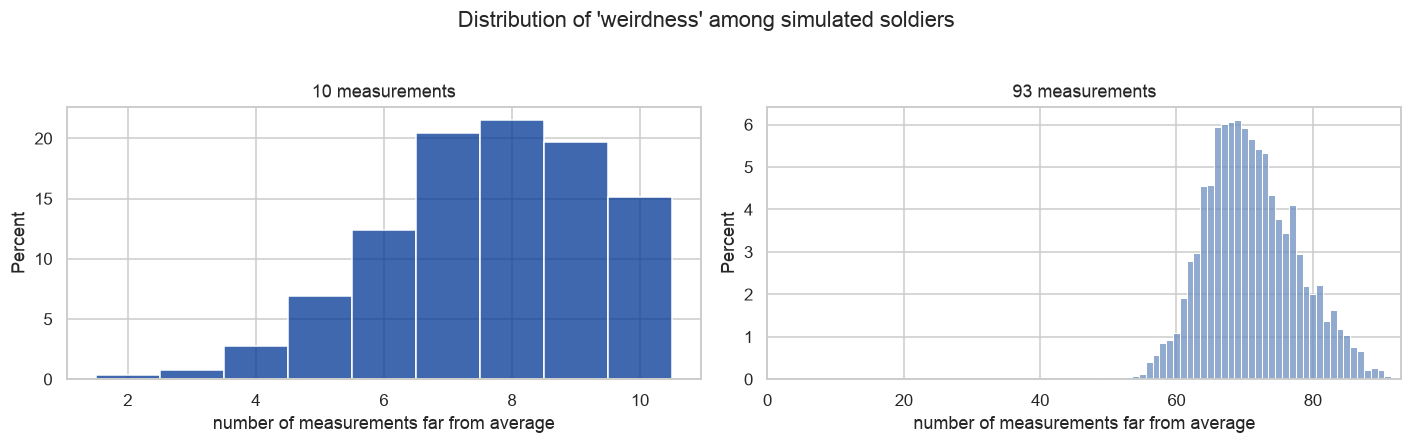

Fewest 'far from average' measurements anyone has, out of 93: 49


In [24]:
weird10 = (~close).sum(axis=1)

# 93 measurements: one general "body size" factor with random loadings (assumption)
n93 = 93
loads = rng.uniform(0.3, 0.85, n93)
size = rng.normal(0, 1, (4086, 1))
z93 = size * loads + rng.normal(0, 1, (4086, n93)) * np.sqrt(1 - loads**2)
weird93 = (np.abs(z93) >= K).sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
sns.histplot(weird10, discrete=True, stat="percent", color=PITT_BLUE, ax=axes[0])
axes[0].set(title="10 measurements", xlabel="number of measurements far from average")
sns.histplot(weird93, discrete=True, stat="percent", color=PALETTE[2], ax=axes[1])
axes[1].set(title="93 measurements", xlabel="number of measurements far from average", xlim=(0, 93))
fig.suptitle("Distribution of 'weirdness' among simulated soldiers", y=1.03)
plt.tight_layout(); plt.show()
print(f"Fewest 'far from average' measurements anyone has, out of 93: {weird93.min()}")

## 5.3 The Big Five personality traits (slides 21–25)
Each trait is measured with **10 survey items** answered on a 5-point scale from −2 to +2, so trait scores range from −20 to +20.

We simulate 100,000 respondents. Each person has a latent level of each trait; each answer is that level plus item-specific noise, cut into five response categories. To mimic **social desirability** (slide 22: few people agree "I insult people", many agree "I have excellent ideas"), the agreeableness and openness items are shifted so that respondents lean toward flattering answers.

**Assumption:** traits are generated independently, consistent with the lecture's description of the Big Five as roughly uncorrelated.

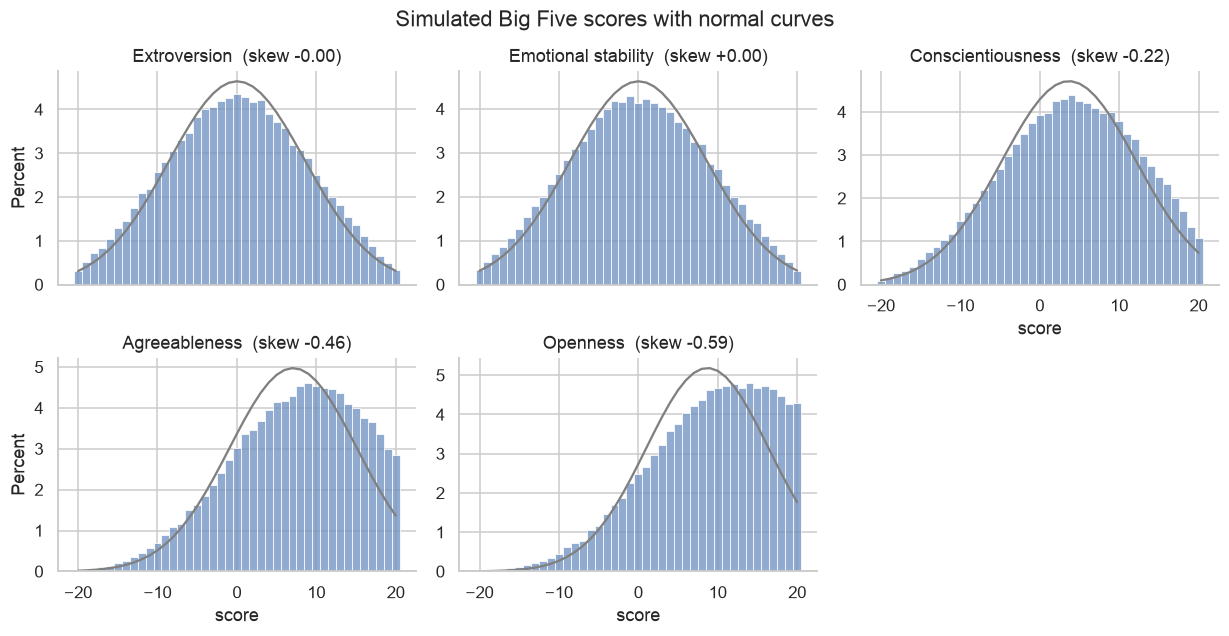

In [25]:
traits = ["Extroversion", "Emotional stability", "Conscientiousness", "Agreeableness", "Openness"]
desirability_shift = {"Extroversion": 0.0, "Emotional stability": 0.0, "Conscientiousness": 0.4,
                      "Agreeableness": 0.8, "Openness": 1.0}
n_resp, n_items = 100_000, 10
cuts = np.array([-1.5, -0.5, 0.5, 1.5])

def trait_scores(shift, rng):
    theta = rng.normal(0, 1, (n_resp, 1))                       # latent trait level
    y = 0.9 * theta + rng.normal(0, 0.8, (n_resp, n_items)) + shift
    answers = np.digitize(y, cuts) - 2                           # categories −2..+2
    return answers.sum(axis=1)

big5 = pd.DataFrame({t: trait_scores(desirability_shift[t], rng) for t in traits})
long5 = big5.melt(var_name="trait", value_name="score")

g = sns.displot(long5, x="score", col="trait", col_wrap=3, discrete=True, stat="percent", common_norm=False,
                height=2.8, aspect=1.35, color=PALETTE[2], facet_kws={"sharey": False})
for ax, t in zip(g.axes.flat, traits):
    xs = np.arange(-20, 21)
    ax.plot(xs, 100 * stats.norm.pdf(xs, big5[t].mean(), big5[t].std()), color="gray", lw=1.5)
    ax.set_title(f"{t}  (skew {stats.skew(big5[t]):+.2f})")
g.figure.suptitle("Simulated Big Five scores with normal curves", y=1.03)
plt.show()

In [26]:
zb = (big5 - big5.mean()) / big5.std()
close5 = zb.abs() < K
stats5 = pd.DataFrame({"Mean": big5.mean(), "Std": big5.std(),
                       "Low": big5.mean() - K * big5.std(), "High": big5.mean() + K * big5.std(),
                       "% in Range": 100 * close5.mean()}).round(1)
display(stats5)

remaining = np.ones(n_resp, dtype=bool); hurdle = []
for t in traits:
    remaining &= close5[t].to_numpy()
    hurdle.append({"Trait": t, "Count": remaining.sum(), "Percentage": 100 * remaining.mean()})
display(pd.DataFrame(hurdle).round(2))

,Mean,Std,Low,High,% in Range
Extroversion,0.0,8.6,-2.5,2.6,21.3
Emotional stability,0.0,8.6,-2.6,2.6,20.9
Conscientiousness,3.7,8.5,1.1,6.2,21.4
Agreeableness,7.1,8.0,4.7,9.5,21.8
Openness,8.7,7.7,6.4,11.0,22.6


,Trait,Count,Percentage
0,Extroversion,21266,21.27
1,Emotional stability,4468,4.47
2,Conscientiousness,989,0.99
3,Agreeableness,239,0.24
4,Openness,44,0.04


Because the scores are whole numbers, the ±0.3σ window contains a whole number of score values, so "% in Range" varies more from trait to trait than it would for continuous data (the real survey shows the same thing, 20–28%). The hurdle collapses the same way it does on slide 24. In this simulation only a few people in ten thousand are close to average on all five traits; the real survey found about one in a thousand (926 people). The exact figure depends on details like how lumpy the scores are, but the conclusion doesn't.

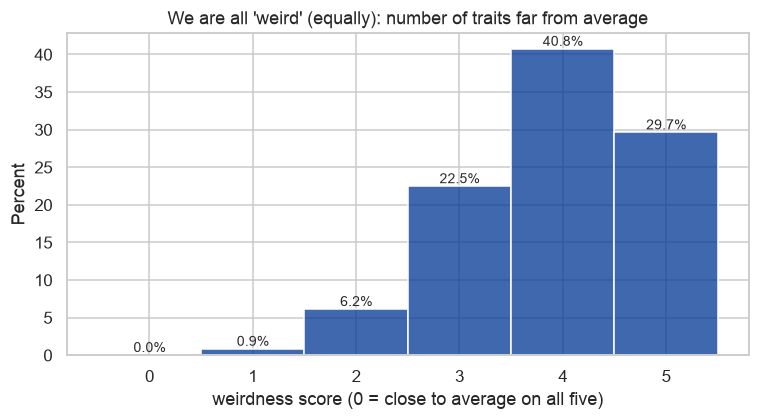

In [27]:
weird_b5 = (~close5).sum(axis=1)
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.histplot(weird_b5, discrete=True, stat="percent", color=PITT_BLUE, ax=ax)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=9)
ax.set(title="We are all 'weird' (equally): number of traits far from average",
       xlabel="weirdness score (0 = close to average on all five)")
plt.show()

**Design implications (slide 27).** When people vary on many dimensions, designing for "the average" (PPE, crash-test dummies, seat and desk heights) systematically excludes most people. Part 7 returns to this with a concrete calculation.

# Part 6 — Sampling and the most dangerous equation (slides 28–31)

## 6.1 Estimates converge, slowly
Slide 28: sum 20 random numbers from (0, 1); the sum has true mean 10 and standard deviation $\sqrt{20/12} \approx 1.29$. Average $N$ such sums and the estimate wobbles around 10, with a spread that shrinks like $1/\sqrt{N}$.

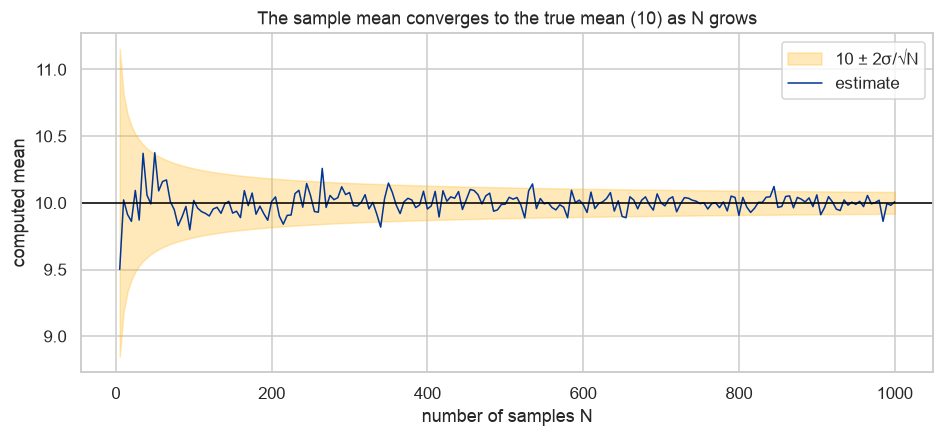

In [28]:
sd_sum = np.sqrt(20 / 12)
Ns = np.arange(5, 1001, 5)
est = [rng.uniform(0, 1, (N, 20)).sum(axis=1).mean() for N in Ns]
conv = pd.DataFrame({"N": Ns, "computed mean": est})

fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(Ns, 10 - 2 * sd_sum / np.sqrt(Ns), 10 + 2 * sd_sum / np.sqrt(Ns),
                color=PITT_GOLD, alpha=0.3, label="10 ± 2σ/√N")
sns.lineplot(data=conv, x="N", y="computed mean", color=PITT_BLUE, lw=1, ax=ax, label="estimate")
ax.axhline(10, color="black", lw=1)
ax.set(title="The sample mean converges to the true mean (10) as N grows",
       xlabel="number of samples N", ylabel="computed mean")
ax.legend(); plt.show()

## 6.2 The sampling distribution: $\sigma_s = \sigma / \sqrt{N}$
**Apples (slide 30).** Population mean $\mu = 100$ g, standard deviation $\sigma = 15$ g. We compare single apples to averages of 100 apples.

> **Note on the slide's numbers.** With $\sigma = 15$, an apple of 115 g is exactly 1σ above the mean, so the chance of an apple that heavy or heavier is about **16%**, not 3%. Likewise, an average of 101.5 g is exactly one standard error above the mean, also about **16%**. The slide's conclusion (the same tail probability now corresponds to a much smaller deviation) is correct; the code below computes the actual values.

Standard error of the mean for N = 100: 1.50 g
P(single apple ≥ 115 g)        theory 15.9%   simulated 16.0%
P(average of 100 ≥ 115 g)      theory 7.6e-24  (that is 10 standard errors)
P(average of 100 ≥ 101.5 g)    theory 15.9%   simulated 15.8%
For a 3% tail you need 1.88σ: 128.2 g for one apple, 102.8 g for the average


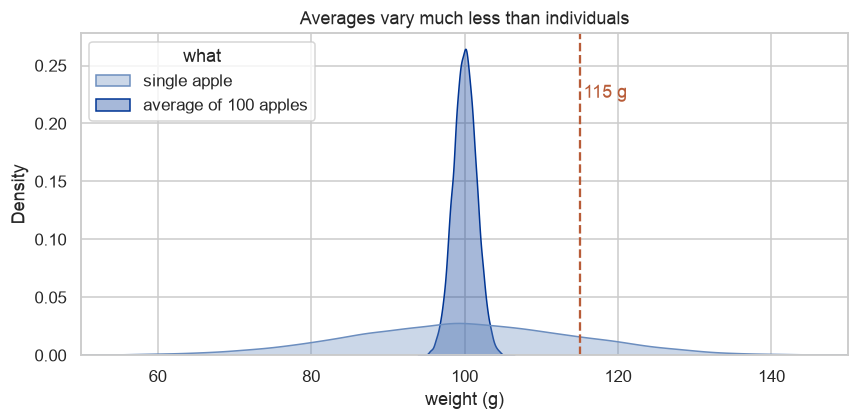

In [29]:
mu, sigma, N = 100, 15, 100
se = sigma / np.sqrt(N)
single = rng.normal(mu, sigma, 100_000)
averages = rng.normal(mu, sigma, (20_000, N)).mean(axis=1)

print(f"Standard error of the mean for N = {N}: {se:.2f} g")
print(f"P(single apple ≥ 115 g)        theory {stats.norm.sf(115, mu, sigma):.1%}   simulated {np.mean(single >= 115):.1%}")
print(f"P(average of 100 ≥ 115 g)      theory {stats.norm.sf(115, mu, se):.1e}  (that is {(115 - mu) / se:.0f} standard errors)")
print(f"P(average of 100 ≥ 101.5 g)    theory {stats.norm.sf(101.5, mu, se):.1%}   simulated {np.mean(averages >= 101.5):.1%}")
print(f"For a 3% tail you need {stats.norm.isf(0.03):.2f}σ: {mu + stats.norm.isf(0.03) * sigma:.1f} g for one apple, "
      f"{mu + stats.norm.isf(0.03) * se:.1f} g for the average")

apples = pd.concat([pd.DataFrame({"weight (g)": single[:20_000], "what": "single apple"}),
                    pd.DataFrame({"weight (g)": averages, "what": "average of 100 apples"})])
fig, ax = plt.subplots(figsize=(9, 3.8))
sns.kdeplot(data=apples, x="weight (g)", hue="what", fill=True, common_norm=False, alpha=0.35,
            palette=[PALETTE[2], PITT_BLUE], ax=ax)
ax.axvline(115, color=PALETTE[3], ls="--"); ax.text(115.5, ax.get_ylim()[1] * 0.8, "115 g", color=PALETTE[3])
ax.set(title="Averages vary much less than individuals", xlim=(50, 150))
plt.show()

## 6.3 Why it is "the most dangerous equation": small schools
Howard Wainer's example (slide 31). Imagine 1,000 schools whose students are **all drawn from the same population**: no school is truly better than any other. School sizes vary widely. We rank schools by their average test score.

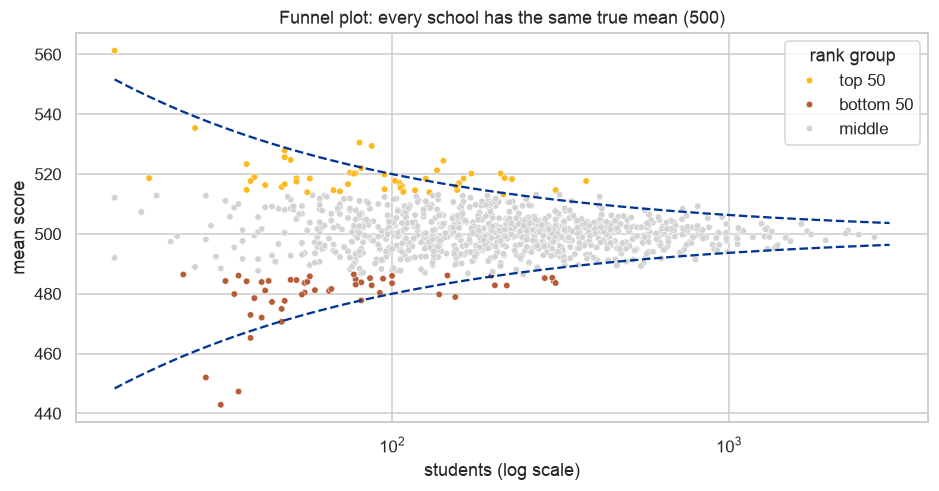

,median school size
rank group,
bottom 50,56.5
middle,203.5
top 50,84.0


In [30]:
n_schools = 1000
sizes = np.clip(rng.lognormal(mean=5.3, sigma=0.9, size=n_schools).astype(int), 15, 3000)
school_means = np.array([rng.normal(500, 100, s).mean() for s in sizes])
schools = pd.DataFrame({"students": sizes, "mean score": school_means})
schools["rank group"] = "middle"
order = schools["mean score"].rank(ascending=False)
schools.loc[order <= 50, "rank group"] = "top 50"
schools.loc[order > n_schools - 50, "rank group"] = "bottom 50"

fig, ax = plt.subplots(figsize=(10, 4.6))
sns.scatterplot(data=schools, x="students", y="mean score", hue="rank group", s=18,
                palette={"top 50": PITT_GOLD, "bottom 50": PALETTE[3], "middle": "lightgray"},
                hue_order=["top 50", "bottom 50", "middle"], ax=ax)
xs = np.geomspace(15, 3000, 200)
for sgn in (1, -1):
    ax.plot(xs, 500 + sgn * 2 * 100 / np.sqrt(xs), color=PITT_BLUE, lw=1.5, ls="--")
ax.set_xscale("log")
ax.set(title="Funnel plot: every school has the same true mean (500)", xlabel="students (log scale)")
plt.show()

display(schools.groupby("rank group")["students"].median().rename("median school size").to_frame())

The best-ranked *and* worst-ranked schools are mostly small, purely because of $\sigma/\sqrt{N}$. A policymaker who looked only at the top of the list would conclude that small schools are better, which is roughly what happened with the Gates Foundation's small-schools initiative. The dashed **funnel** lines ($\pm 2\sigma/\sqrt{N}$) show the range we'd expect from chance alone; points inside the funnel are not evidence of anything.


# Part 7 — Computational social science: looking at the distribution before drawing conclusions

The second half of the lecture argued that data is constructed, that what is missing matters, and that statistical tools produce educated guesses rather than certainties. This part works through seven short case studies from computational social science. Each follows the same pattern:

1. **A tempting conclusion** someone might draw from a single summary number.
2. **The distribution**, plotted.
3. **What the distribution actually supports.**

All data are simulated so the "true" answer is known; that is what lets us see where the tempting conclusion goes wrong.

| Case | Lesson from the lecture |
|---|---|
| 7.1 Household income | Close to the mean ≠ common (slide 8) |
| 7.2 Social media attention | The CLT needs finite variance (slide 4) |
| 7.3 Online ratings | Who chooses to be measured (slides 33–36) |
| 7.4 Election polls | σ/√N fixes noise, not bias (slides 29–30) |
| 7.5 Neighborhood crime statistics | Small numbers + absence of data is data (slides 31, 42) |
| 7.6 Algorithmic risk scores | Tails decide who is affected (slides 38–40) |
| 7.7 Designing for the average | Responsible design (slide 27) |

## 7.1 Household income: when the mean describes almost nobody
**Tempting conclusion:** "The average household in our city earns \$X, so a typical family can afford a rent of \$X/40 per month."

Incomes are not sums of many small independent pieces; raises, returns on wealth, and career advantages *compound*. That produces a right-skewed, roughly **log-normal** body with an even heavier **Pareto** tail at the top. We simulate 200,000 households that way.

Mean income:    $91,777
Median income:  $62,561
Share of households earning less than the mean: 69.3%
Share of all income received by the top 1%:     12.1%


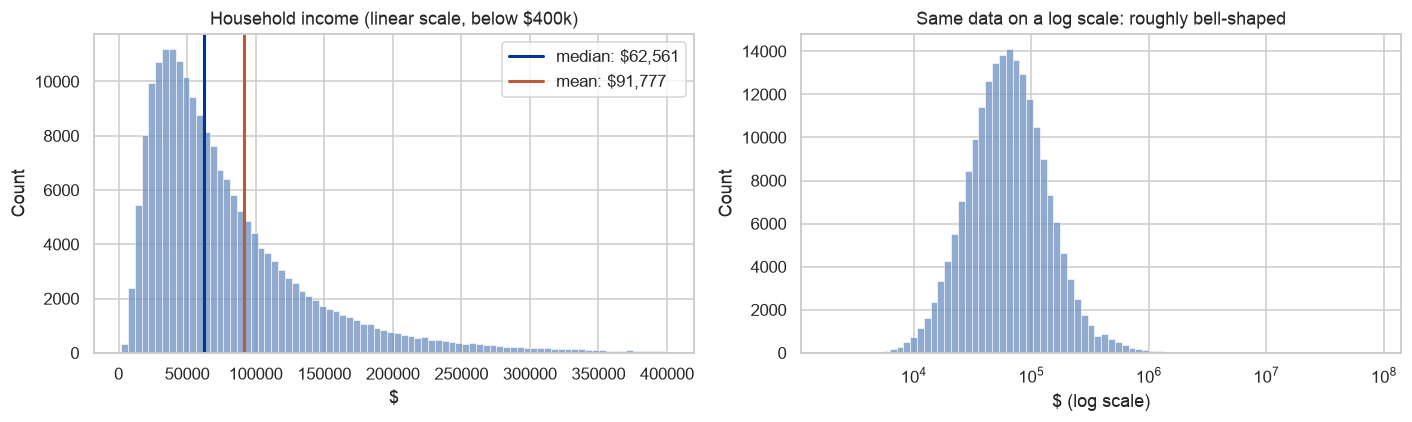

In [31]:
n_hh = 200_000
body = rng.lognormal(mean=np.log(62_000), sigma=0.75, size=n_hh)
top = rng.random(n_hh) < 0.01                                   # top 1% follow a Pareto tail
body[top] = 400_000 * (1 + rng.pareto(1.6, top.sum()))
income = pd.Series(body, name="household income ($)")

mean_inc, median_inc = income.mean(), income.median()
print(f"Mean income:    ${mean_inc:,.0f}")
print(f"Median income:  ${median_inc:,.0f}")
print(f"Share of households earning less than the mean: {np.mean(income < mean_inc):.1%}")
print(f"Share of all income received by the top 1%:     {income[income >= income.quantile(0.99)].sum() / income.sum():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(income[income < 400_000], bins=80, color=PALETTE[2], ax=axes[0])
for val, lab, col in [(median_inc, "median", PITT_BLUE), (mean_inc, "mean", PALETTE[3])]:
    axes[0].axvline(val, color=col, lw=2, label=f"{lab}: ${val:,.0f}")
axes[0].set(title="Household income (linear scale, below $400k)", xlabel="$")
axes[0].legend()
sns.histplot(income, bins=80, log_scale=True, color=PALETTE[2], ax=axes[1])
axes[1].set(title="Same data on a log scale: roughly bell-shaped", xlabel="$ (log scale)")
plt.tight_layout(); plt.show()

**What the distribution supports.** Most households earn less than the mean, and the mean is pulled up by a small group at the top. For "typical" questions, report the **median** and percentiles (e.g., the 25th and 75th). On a log scale income looks roughly normal, a hint that it is generated by *multiplying* factors, like the weight example in Part 3.

## 7.2 Social media attention: when the CLT doesn't save you
**Tempting conclusion:** "We sampled 1,000 accounts; the average account has about 180 followers, give or take a little."

Follower counts, retweets, and video views typically follow a **power law**: a few accounts have enormous audiences. For a power law with tail exponent $\alpha < 2$ the variance is infinite, which violates a condition of the Central Limit Theorem (slide 4), and a small set of accounts "contributes most of the variance."

Median followers: 81   Mean followers: 183
Top 1% of accounts hold 30% of all followers


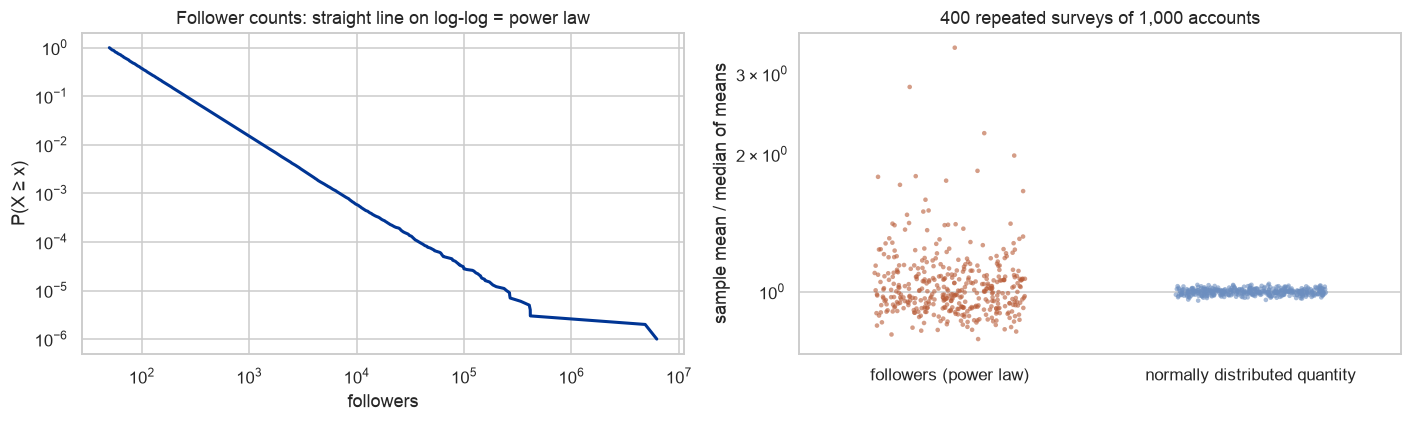

Spread of the sample means (max/min): power law 4.3×, normal 1.09×


In [32]:
alpha = 1.4
followers = np.floor(50 * (1 + rng.pareto(alpha, 1_000_000))).astype(int)   # a "platform" of 1M accounts

sorted_f = np.sort(followers)[::-1]
top1_share = sorted_f[: len(sorted_f) // 100].sum() / sorted_f.sum()
print(f"Median followers: {np.median(followers):,.0f}   Mean followers: {followers.mean():,.0f}")
print(f"Top 1% of accounts hold {top1_share:.0%} of all followers")

# Complementary CDF on log-log axes: a straight line signals a power law
ccdf = pd.DataFrame({"followers": sorted_f, "P(X ≥ x)": np.arange(1, len(sorted_f) + 1) / len(sorted_f)})
ccdf = ccdf.iloc[np.unique(np.geomspace(1, len(ccdf), 400).astype(int) - 1)]

# Repeat the "survey of 1,000 accounts" many times; compare with a normal quantity
samples = pd.DataFrame({
    "followers (power law)": [rng.choice(followers, 1000).mean() for _ in range(400)],
    "normally distributed quantity": [rng.normal(180, 90, 1000).mean() for _ in range(400)],
})
samples_rel = samples / samples.median()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.lineplot(data=ccdf, x="followers", y="P(X ≥ x)", color=PITT_BLUE, lw=2, ax=axes[0])
axes[0].set(xscale="log", yscale="log", title="Follower counts: straight line on log-log = power law")
sns.stripplot(data=samples_rel.melt(var_name="quantity", value_name="sample mean / median of means"),
              x="quantity", y="sample mean / median of means", hue="quantity", legend=False,
              palette=[PALETTE[3], PALETTE[2]], size=3, alpha=0.6, jitter=0.25, ax=axes[1])
axes[1].set(yscale="log", title="400 repeated surveys of 1,000 accounts", xlabel="")
plt.tight_layout(); plt.show()
print("Spread of the sample means (max/min):",
      f"power law {samples.iloc[:, 0].max() / samples.iloc[:, 0].min():.1f}×,",
      f"normal {samples.iloc[:, 1].max() / samples.iloc[:, 1].min():.2f}×")

**What the distribution supports.** For heavy-tailed attention data, a sample mean can swing wildly depending on whether a celebrity account happened to be sampled. Report medians, percentiles, or the share held by the top accounts, and plot the tail on log-log axes. "The average user" on a platform is a statistical fiction, just like the average soldier.

## 7.3 Online ratings: who chooses to be measured?
**Tempting conclusion:** "The reviews show customers are polarized: most of them either love this product or hate it."

Customers' actual satisfaction might be roughly normal. But people with **extreme** experiences are much more likely to leave a review. Self-selection turns a bell curve into the familiar **J-shaped** distribution of online reviews. The reviews are *found* data (slide 34), shaped by who decided to write.

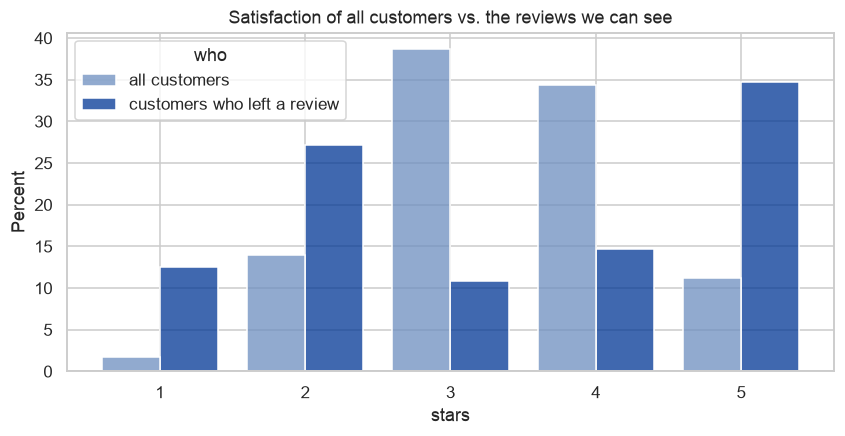

Reviews written: 16,772 of 200,000 customers (8.4%)
Mean stars, all customers: 3.39   Mean stars, reviewers: 3.32
Share of 3-star ratings — all customers: 39%, reviewers: 11%


In [33]:
n_cust = 200_000
satisfaction = rng.normal(3.4, 0.9, n_cust)                      # latent satisfaction
stars = np.clip(np.rint(satisfaction), 1, 5).astype(int)
z_sat = (satisfaction - satisfaction.mean()) / satisfaction.std()
p_review = np.clip(0.01 + 0.06 * np.abs(z_sat) ** 2.5, 0, 0.9)  # extreme experiences post more
reviewed = rng.random(n_cust) < p_review

ratings = pd.concat([pd.DataFrame({"stars": stars, "who": "all customers"}),
                     pd.DataFrame({"stars": stars[reviewed], "who": "customers who left a review"})])
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=ratings, x="stars", hue="who", discrete=True, stat="percent", common_norm=False,
             multiple="dodge", shrink=0.8, palette=[PALETTE[2], PITT_BLUE], ax=ax)
ax.set(title="Satisfaction of all customers vs. the reviews we can see", xticks=range(1, 6))
plt.show()

print(f"Reviews written: {reviewed.sum():,} of {n_cust:,} customers ({reviewed.mean():.1%})")
print(f"Mean stars, all customers: {stars.mean():.2f}   Mean stars, reviewers: {stars[reviewed].mean():.2f}")
print(f"Share of 3-star ratings — all customers: {np.mean(stars == 3):.0%}, reviewers: {np.mean(stars[reviewed] == 3):.0%}")

**What the distribution supports.** The average of the reviews can be similar to the true average while the *shape* is completely different: most real customers are in the middle, but the middle is almost invisible in the reviews. Conclusions about polarization or "love it or hate it" products drawn from review data may say more about who writes reviews than about customers. Here, the absence of 3-star reviews is itself data.

## 7.4 Election polls: bigger samples shrink noise, not bias
**Tempting conclusion:** "Our poll of 2,500 people has a margin of error of ±2 points, so the result is reliable."

The margin of error comes straight from $\sigma/\sqrt{N}$: for a proportion $p$, the standard error is $\sqrt{p(1-p)/N}$. But that formula assumes a **random sample**. If one candidate's supporters are less likely to answer pollsters (nonresponse bias), a larger sample just gives a more confident wrong answer.

Assume the true support for candidate A is **52%**.

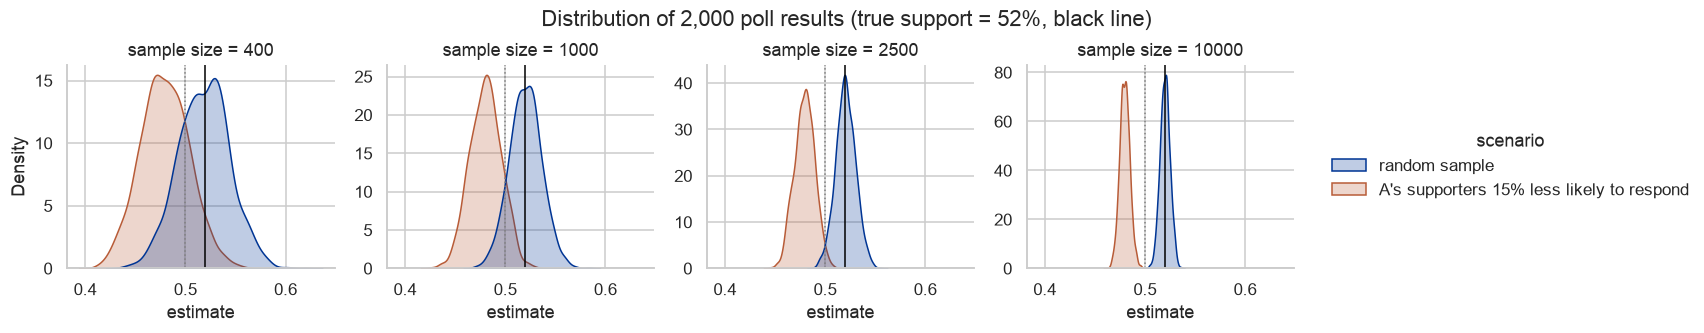

mean_estimate  \
scenario                                  sample size                  
A's supporters 15% less likely to respond 400                  0.479   
                                          1000                 0.480   
                                          2500                 0.479   
                                          10000                0.480   
random sample                             400                  0.518   
                                          1000                 0.520   
                                          2500                 0.520   
                                          10000                0.520   

                                                       std_error  \
scenario                                  sample size              
A's supporters 15% less likely to respond 400              0.024   
                                          1000             0.016   
                                          2500             0.010   
                                          10000            0.005   
random sample                             400              0.026   
                                          1000             0.016   
                                          2500             0.010   
                                          10000            0.005   

                                                       share_showing_wrong_leader  \
scenario                                  sample size                               
A's supporters 15% less likely to respond 400                               0.786   
                                          1000                              0.885   
                                          2500                              0.980   
                                          10000                             1.000   
random sample                             400                               0.228   
                                          1000                              0.102   
                                          2500                              0.022   
                                          10000                             0.000   

                                                       reported ±MoE (95%)  
scenario                                  sample size                       
A's supporters 15% less likely to respond 400                        0.049  
                                          1000                       0.031  
                                          2500                       0.020  
                                          10000                      0.010  
random sample                             400                        0.049  
                                          1000                       0.031  
                                          2500                       0.020  
                                          10000                      0.010

In [34]:
p_true = 0.52
rows = []
for n_poll in [400, 1000, 2500, 10_000]:
    for scenario, p_obs in [("random sample", p_true),
                            ("A's supporters 15% less likely to respond", None)]:
        if p_obs is None:   # response rates: A supporters 0.85 × B supporters
            p_obs = 0.85 * p_true / (0.85 * p_true + (1 - p_true))
        est = rng.binomial(n_poll, p_obs, 2000) / n_poll
        rows.append(pd.DataFrame({"sample size": n_poll, "scenario": scenario, "estimate": est}))
polls = pd.concat(rows, ignore_index=True)

g = sns.displot(polls, x="estimate", hue="scenario", col="sample size", kind="kde", fill=True,
                common_norm=False, height=2.9, aspect=1.05, palette=[PITT_BLUE, PALETTE[3]],
                facet_kws={"sharey": False})
for ax in g.axes.flat:
    ax.axvline(p_true, color="black", lw=1)
    ax.axvline(0.5, color="gray", ls=":", lw=1)
g.figure.suptitle("Distribution of 2,000 poll results (true support = 52%, black line)", y=1.04)
plt.show()

summary = (polls.assign(wrong_leader=polls.estimate < 0.5)
           .groupby(["scenario", "sample size"])
           .agg(mean_estimate=("estimate", "mean"), std_error=("estimate", "std"),
                share_showing_wrong_leader=("wrong_leader", "mean")))
summary["reported ±MoE (95%)"] = 1.96 * np.sqrt(0.25 / summary.index.get_level_values("sample size"))
display(summary.round(3))

**What the distribution supports.** With a random sample, quadrupling the sample size halves the spread, exactly as $\sigma/\sqrt{N}$ predicts, and the polls increasingly point to the right winner. With nonresponse bias, the whole distribution is centered in the wrong place, and *larger* samples make it more likely, not less, that a poll shows the wrong leader. The reported margin of error covers sampling noise only.

## 7.5 Neighborhood crime statistics: small numbers and missing reports
**Tempting conclusion:** "These ten neighborhoods have the highest crime rates in the city; send more patrols there."

We simulate 400 neighborhoods that **all have the same true rate** of incidents (30 per 1,000 residents per year). Two things vary: population size (the small-numbers problem from slide 31), and the probability an incident is **reported** to police. In half the neighborhoods, where residents have more trust in police or more patrols already, 80% of incidents are recorded; in the others, 45%.

The 10 'highest-crime' neighborhoods by recorded rate:
  median population 763 (city median 2,514)
  high-reporting share: 100%
True rate in every neighborhood: 30 per 1,000
Mean recorded rate by reporting level:
reporting rate
high (80%)    24.1
low (45%)     13.7


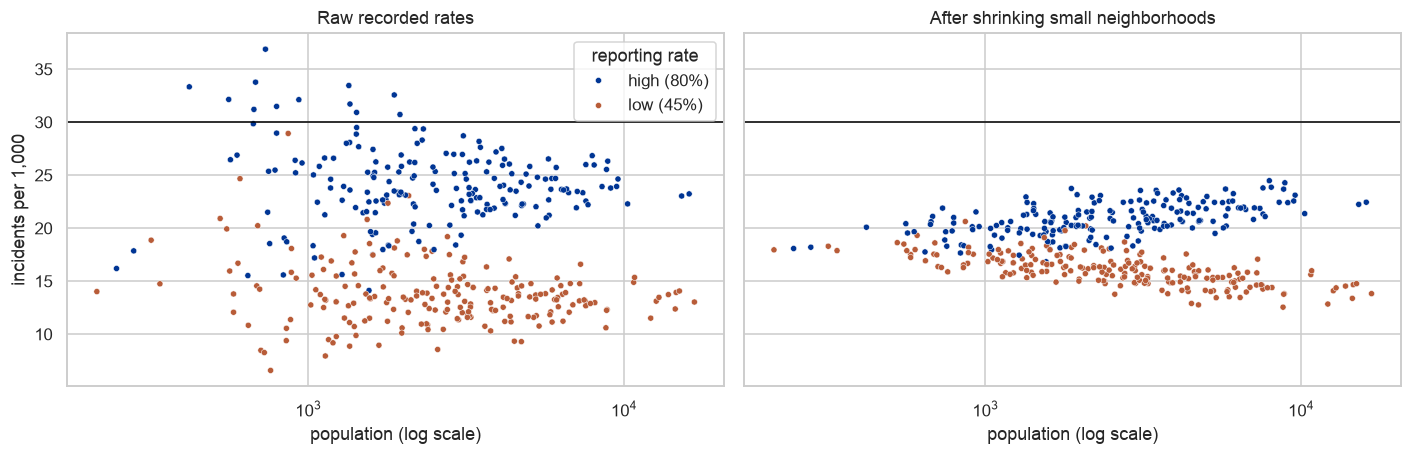

In [35]:
n_nb = 400
pop = np.clip(rng.lognormal(np.log(2500), 0.8, n_nb).astype(int), 200, 30_000)
true_rate = 0.030
report_prob = np.where(rng.random(n_nb) < 0.5, 0.80, 0.45)
incidents = rng.poisson(true_rate * pop)
recorded = rng.binomial(incidents, report_prob)

nb = pd.DataFrame({"population": pop, "reporting rate": np.where(report_prob > 0.6, "high (80%)", "low (45%)"),
                   "recorded per 1,000": 1000 * recorded / pop})

# Empirical-Bayes style shrinkage: pull small neighborhoods toward the citywide rate
city_rate = recorded.sum() / pop.sum()
prior_strength = 3000                       # "pseudo-residents"; larger = more shrinkage
nb["shrunk per 1,000"] = 1000 * (recorded + prior_strength * city_rate) / (pop + prior_strength)

top10 = nb.nlargest(10, "recorded per 1,000")
print("The 10 'highest-crime' neighborhoods by recorded rate:")
print(f"  median population {top10.population.median():,.0f} (city median {nb.population.median():,.0f})")
print(f"  high-reporting share: {np.mean(top10['reporting rate'] == 'high (80%)'):.0%}")
print(f"True rate in every neighborhood: {1000 * true_rate:.0f} per 1,000")
print("Mean recorded rate by reporting level:")
print(nb.groupby("reporting rate")["recorded per 1,000"].mean().round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, col, title in [(axes[0], "recorded per 1,000", "Raw recorded rates"),
                       (axes[1], "shrunk per 1,000", "After shrinking small neighborhoods")]:
    sns.scatterplot(data=nb, x="population", y=col, hue="reporting rate", s=16,
                    palette=[PITT_BLUE, PALETTE[3]], ax=ax)
    ax.axhline(1000 * true_rate, color="black", lw=1, label="true rate (everywhere)")
    ax.set(xscale="log", title=title, xlabel="population (log scale)", ylabel="incidents per 1,000")
axes[1].legend_.remove()
plt.tight_layout(); plt.show()

**What the distribution supports.** Every neighborhood has the same underlying rate, yet the recorded data shows two clusters and a wide funnel. Small neighborhoods dominate both ends of the ranking. **Shrinkage** (an empirical-Bayes adjustment that borrows strength from the citywide rate) tames the small-numbers problem, but no statistical adjustment fixes the reporting gap: in the recorded data, high-reporting areas look like higher-crime areas.

If patrols are then sent to neighborhoods with more recorded crime, more incidents are recorded there, and the gap grows: a feedback loop. Recorded crime measures crime *and* the act of observing it, which is next week's question: who is observing?

## 7.6 Algorithmic risk scores: the tails decide who is affected
**Tempting conclusion:** "Our model's risk scores have the same average for both groups among people who did *not* go on to default, so the model treats the groups the same."

Suppose a lending model was trained mostly on group A. For group B it has less data, so its scores for B are **noisier**, a direct consequence of $\sigma/\sqrt{N}$ (slide 29). Among applicants who would repay, both groups get the same average score, but group B's scores are more spread out. Applicants above a fixed threshold of 0.6 are flagged as high risk.

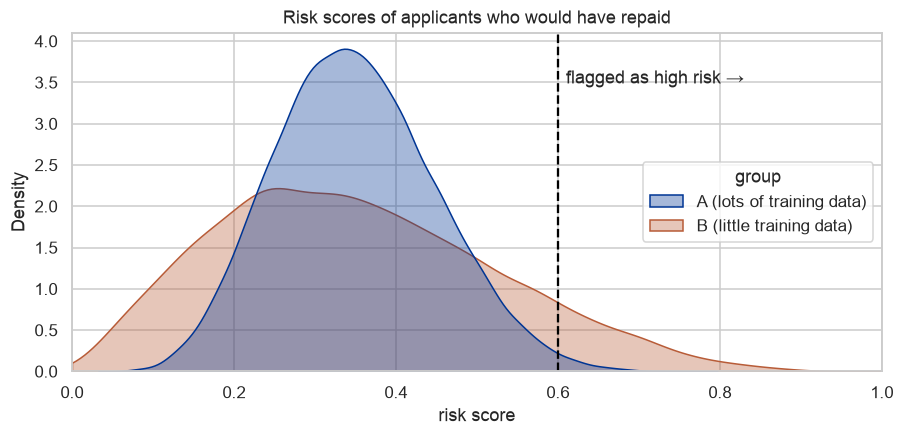

,mean_score,sd,false_positive_rate
group,,,
A (lots of training data),0.35,0.099,0.008
B (little training data),0.35,0.171,0.091


Group B's false-positive rate is 11× group A's, with identical average scores.


In [36]:
n_a, n_b = 40_000, 8_000
neg = pd.concat([
    # beta distributions keep scores in [0, 1]; both have mean 0.35 (SDs 0.10 and 0.17)
    pd.DataFrame({"risk score": rng.beta(7.61, 14.14, n_a), "group": "A (lots of training data)"}),
    pd.DataFrame({"risk score": rng.beta(2.40, 4.47, n_b), "group": "B (little training data)"}),
], ignore_index=True)
threshold = 0.6

fig, ax = plt.subplots(figsize=(9.5, 4))
sns.kdeplot(data=neg, x="risk score", hue="group", fill=True, common_norm=False, alpha=0.35,
            palette=[PITT_BLUE, PALETTE[3]], clip=(0, 1), ax=ax)
ax.axvline(threshold, color="black", ls="--")
ax.text(threshold + 0.01, ax.get_ylim()[1] * 0.85, "flagged as high risk →")
ax.set(title="Risk scores of applicants who would have repaid", xlim=(0, 1))
plt.show()

fpr = (neg.assign(flagged=neg["risk score"] > threshold)
       .groupby("group").agg(mean_score=("risk score", "mean"), sd=("risk score", "std"),
                              false_positive_rate=("flagged", "mean")))
display(fpr.round(3))
print(f"Group B's false-positive rate is {fpr.false_positive_rate.iloc[1] / fpr.false_positive_rate.iloc[0]:.0f}× group A's, "
      "with identical average scores.")

**What the distribution supports.** Comparing averages hides the problem completely. Decisions happen at a **threshold**, out in the tail, and a wider distribution puts many more people past it. Auditing an algorithm means comparing whole distributions and error rates by group, not just means. It also raises the data question from slide 33: who selected the training data, and who was left out?

## 7.7 Designing for the average: who does the product fit?
**Tempting conclusion:** "We designed our workstation to accommodate people from the 5th to the 95th percentile of height, so it fits 90% of users."

That's true only for the population the percentiles came from. Using the simulated heights from Part 3, we design for the 5th–95th percentile of **men** (a historically common choice for military and industrial equipment) and check who is actually accommodated.

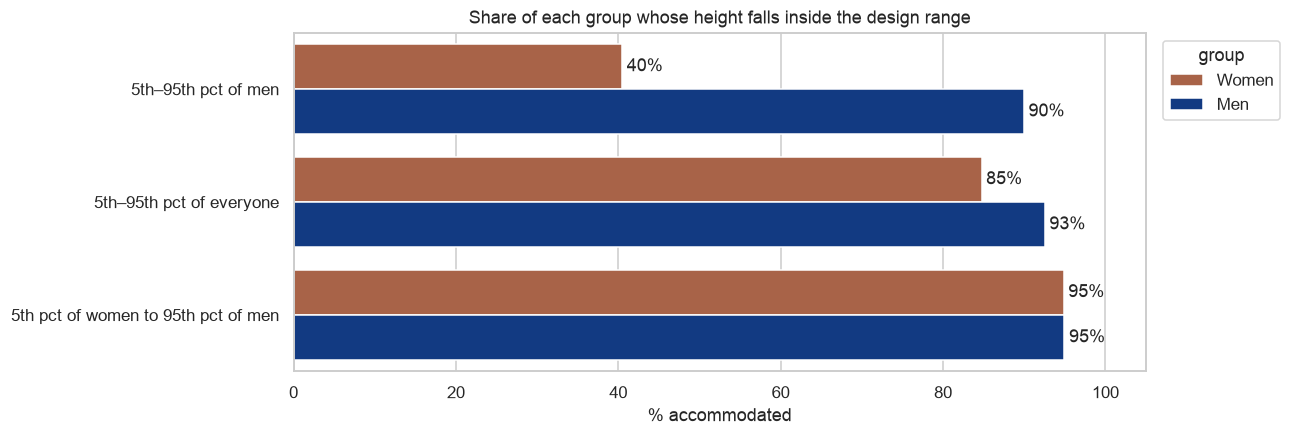

group,Men,Women
design range,,
5th pct of women to 95th pct of men,95.0,94.9
5th–95th pct of everyone,92.5,84.7
5th–95th pct of men,90.0,40.5


In [37]:
designs = {
    "5th–95th pct of men": np.percentile(male_h, [5, 95]),
    "5th–95th pct of everyone": np.percentile(np.concatenate([male_h, female_h]), [5, 95]),
    "5th pct of women to 95th pct of men": [np.percentile(female_h, 5), np.percentile(male_h, 95)],
}
rows = []
for name, (lo, hi) in designs.items():
    for grp, h in [("Women", female_h), ("Men", male_h)]:
        rows.append({"design range": name, "group": grp,
                     "% accommodated": 100 * np.mean((h >= lo) & (h <= hi)),
                     "range (cm)": f"{lo:.0f}–{hi:.0f}"})
fit = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=fit, y="design range", x="% accommodated", hue="group",
            palette=[PALETTE[3], PITT_BLUE], ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f%%", padding=3)
ax.set(xlim=(0, 105), title="Share of each group whose height falls inside the design range", ylabel="")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1.01, 1))
plt.show()
display(fit.pivot(index="design range", columns="group", values="% accommodated").round(1))

**What the distribution supports.** A "90% of users" design built on the male distribution accommodates only a minority of women. Choosing whose distribution defines the range is a design decision with real consequences: PPE that doesn't fit, crash-test dummies that don't represent many occupants, controls that are out of reach. And height is just *one* dimension; Part 5 showed that fitting several at once excludes far more people.

---
# Part 8 — Summary and exercises

## Before drawing a conclusion from a distribution, ask:
1. **What is its shape?** Plot it (histogram, ECDF, Q–Q plot). Is it symmetric, skewed, heavy-tailed, or bimodal? Is the mean a good summary, or should you use the median and percentiles?
2. **Is it a sum or a product?** Sums of many small independent effects tend toward normal; products tend toward log-normal; "rich get richer" processes produce power laws.
3. **How big is each group?** Small groups produce extreme values by chance ($\sigma/\sqrt{N}$). Use funnel plots and shrinkage before ranking.
4. **Are the observations independent?** Shared shocks and social influence make totals far more variable than the CLT predicts.
5. **How many things did you look at?** With enough comparisons, rare events are guaranteed.
6. **Who was measured, by whom, and who is missing?** Sampling, self-selection, reporting rates, and training data shape the distribution before any statistics are computed.

## Exercises
1. **CLT speed.** In Part 2.1, add a lognormal distribution (`rng.lognormal(0, 1, size)`). How large must $N$ be before the skewness of the standardized sum drops below 0.2?
2. **The average man, revisited.** Change `factor_corr` and the loadings in Part 5.1. How strong must the correlations be for at least 10 of the 4,086 simulated men to be "average" on all ten measurements?
3. **Town spending.** Replace the random Alice-type spending with Alice's strict alternating pattern (\$50, \$150, \$50, …) for every Alice-type resident, all in phase. What happens to the distribution of the weekly total? Which CLT condition is violated?
4. **Polls.** In 7.4, find the smallest response-rate gap that makes a poll of 10,000 people show the wrong leader more than half the time.
5. **Shrinkage.** In 7.5, vary `prior_strength`. What happens with a value of 0? Of 100,000? How would you choose it in practice? (Hint: look up "empirical Bayes" or "beta-binomial model.")
6. **Fairness thresholds.** In 7.6, find a separate threshold for group B that equalizes the false-positive rates. Then simulate applicants who *would* default for both groups and compare the true-positive rates. What trade-off appears?
7. **Your own data.** Pick a dataset from your field (survey responses, social media metrics, administrative records). Plot the distribution of one key variable, decide which of the checklist questions above matter most, and write a three-sentence conclusion that the distribution actually supports.